# ISO V4 Output Analysis

This notebook is the collaborative analysis surface for the outputs produced by the flow documented in `ISO_V4_PROCESSING_README.md`.

Targets:
- ObsDb-style SQLite output (`iso_v4_*.sqlite`)
- Aggregated HDF5 noise products (`noise_aggregation_*.h5`)

The notebook is designed to be safe to open before data exist locally. Cells check paths and degrade gracefully so we can iterate on plots and tables without breaking the notebook.

In [1]:
from dataclasses import dataclass, asdict
from pathlib import Path
import csv
import json
import re
import sqlite3
from typing import Any, Iterable

import h5py
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('default')
np.random.seed(0)

NOTEBOOK_ROOT = Path('/home/ms3067/so_data_exploration/tiger/202601_v4')
DEFAULT_OUTPUT_ROOT = NOTEBOOK_ROOT / 'plots' / 'analysis'


## Set Up Notebook Environment

This section defines deterministic notebook settings and reusable constants.

## Define Inputs And Configuration

Update these paths before running analysis against a specific SATp1 or SATp3 output directory.

In [2]:
@dataclass
class AnalysisConfig:
    telescope: str = 'satp1'
    sqlite_path: str = '/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/databases/iso_v4_satp1_20260417.sqlite'
    aggregation_dir: str = '/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation'
    output_dir: str = str(DEFAULT_OUTPUT_ROOT / 'satp1')
    save_artifacts: bool = False
    expected_bands: tuple[str, ...] = ('f090', 'f150')


config = AnalysisConfig()
config_dict = asdict(config)
config_dict

{'telescope': 'satp1',
 'sqlite_path': '/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/databases/iso_v4_satp1_20260417.sqlite',
 'aggregation_dir': '/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation',
 'output_dir': '/home/ms3067/so_data_exploration/tiger/202601_v4/plots/analysis/satp1',
 'save_artifacts': False,
 'expected_bands': ('f090', 'f150')}

**Comment**
I would like the all of the output products to write into `/scratch/gpfs/SIMONSOBS/users/ms3067/iso_stats/v4_tests/satp1/analysis` or subdirectories of there. So based on the directory where the aggregated sqlite + h5 are stored.

## Implement Core Data Structures

The README flow writes one ObsDb-style table with many generated columns. The helpers below inspect the schema dynamically so the notebook does not depend on removed legacy analyzers.

In [ ]:
DET_COL_RE = re.compile(r'^det_(?P<index>\d+)_(?P<name>.+)_ndets$')
NOISE_COL_RE = re.compile(r'^noise_(?P<pol>[TQU])_(?P<metric>.+)$')


@dataclass
class SqliteInspection:
    exists: bool
    table_names: list[str]
    obs_columns: list[str]
    detector_columns: list[str]
    noise_columns: list[str]


@dataclass
class Hdf5Inspection:
    exists: bool
    path: str
    datasets: list[str]
    n_obs_ids: int | None = None
    n_det_ids: int | None = None


def path_status(path_like: str | Path) -> dict[str, Any]:
    path = Path(path_like)
    return {
        'path': str(path),
        'exists': path.exists(),
        'is_file': path.is_file(),
        'is_dir': path.is_dir(),
    }


def fetch_all_dicts(conn: sqlite3.Connection, query: str) -> list[dict[str, Any]]:
    conn.row_factory = sqlite3.Row
    return [dict(row) for row in conn.execute(query).fetchall()]


def maybe_float(value: Any) -> float | None:
    try:
        if value is None:
            return None
        return float(value)
    except (TypeError, ValueError):
        return None


def mean_or_none(values: Iterable[Any]) -> float | None:
    numeric = [value for value in (maybe_float(v) for v in values) if value is not None and not np.isnan(value)]
    if not numeric:
        return None
    return float(np.mean(numeric))


def median_or_none(values: Iterable[Any]) -> float | None:
    numeric = [value for value in (maybe_float(v) for v in values) if value is not None and not np.isnan(value)]
    if not numeric:
        return None
    return float(np.median(numeric))


def inspect_sqlite(sqlite_path: str | Path) -> SqliteInspection:
    path = Path(sqlite_path)
    if not path.exists():
        return SqliteInspection(False, [], [], [], [])

    with sqlite3.connect(path) as conn:
        table_rows = fetch_all_dicts(conn, "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")
        table_names = [row['name'] for row in table_rows]

        obs_columns: list[str] = []
        if 'obs' in table_names:
            pragma_rows = fetch_all_dicts(conn, 'PRAGMA table_info(obs)')
            obs_columns = [row['name'] for row in pragma_rows]

    detector_columns = [col for col in obs_columns if DET_COL_RE.match(col)]
    noise_columns = [col for col in obs_columns if NOISE_COL_RE.match(col)]
    return SqliteInspection(True, table_names, obs_columns, detector_columns, noise_columns)


def parse_detector_columns(columns: Iterable[str]) -> list[dict[str, Any]]:
    parsed: list[dict[str, Any]] = []
    for col in columns:
        match = DET_COL_RE.match(col)
        if match:
            parsed.append({
                'step_index': int(match.group('index')),
                'step_name': match.group('name'),
                'column': col,
            })
    return sorted(parsed, key=lambda item: item['step_index'])


def summarize_noise_columns(columns: Iterable[str]) -> list[dict[str, str]]:
    rows = []
    for col in columns:
        match = NOISE_COL_RE.match(col)
        if match:
            rows.append({'column': col, 'pol': match.group('pol'), 'metric': match.group('metric')})
    return sorted(rows, key=lambda item: (item['pol'], item['metric']))


def find_aggregation_files(aggregation_dir: str | Path) -> list[Path]:
    agg_dir = Path(aggregation_dir)
    if not agg_dir.exists():
        return []
    return sorted(agg_dir.glob('noise_aggregation_*.h5'))


def inspect_hdf5(hdf5_path: str | Path) -> Hdf5Inspection:
    path = Path(hdf5_path)
    if not path.exists():
        return Hdf5Inspection(False, str(path), [])

    with h5py.File(path, 'r') as handle:
        datasets = sorted(list(handle.keys()))
        n_obs_ids = len(handle['obs_ids']) if 'obs_ids' in handle else None
        n_det_ids = len(handle['det_ids']) if 'det_ids' in handle else None
    return Hdf5Inspection(True, str(path), datasets, n_obs_ids, n_det_ids)


## Build The First Working Function

The first working function returns a compact, inspectable summary bundle from the SQLite database and any aggregation HDF5 files it finds.

**Comment** This may need to be changed in the scraping script.

In [ ]:
def build_summary_bundle(cfg: AnalysisConfig) -> dict[str, Any]:
    """Build a minimal analysis bundle from README flow outputs.

    Parameters
    ----------
    cfg : AnalysisConfig
        Notebook configuration with SQLite and aggregation paths.

    Returns
    -------
    dict[str, Any]
        Dictionary containing path status, schema inspection, optional row-based
        summaries, and HDF5 inspections. Missing files are represented cleanly
        instead of raising errors so the notebook can be developed before data
        are local.
    """
    bundle: dict[str, Any] = {
        'config': asdict(cfg),
        'sqlite_status': path_status(cfg.sqlite_path),
        'aggregation_status': path_status(cfg.aggregation_dir),
    }

    sqlite_info = inspect_sqlite(cfg.sqlite_path)
    bundle['sqlite_info'] = sqlite_info
    bundle['detector_steps'] = parse_detector_columns(sqlite_info.detector_columns)
    bundle['noise_columns'] = summarize_noise_columns(sqlite_info.noise_columns)

    if sqlite_info.exists and 'obs' in sqlite_info.table_names:
        with sqlite3.connect(cfg.sqlite_path) as conn:
            obs_rows = fetch_all_dicts(conn, 'SELECT * FROM obs')
        bundle['obs_rows'] = obs_rows

        success_counts: dict[int, int] = {}
        for row in obs_rows:
            raw_value = row.get('success', -1)
            try:
                key = int(raw_value if raw_value is not None else -1)
            except (TypeError, ValueError):
                key = -1
            success_counts[key] = success_counts.get(key, 0) + 1
        bundle['success_summary'] = [
            {'success': key, 'count': success_counts[key]}
            for key in sorted(success_counts)
        ]

        valid_obs_rows = [row for row in obs_rows if row.get('success') == 1] if obs_rows and 'success' in obs_rows[0] else obs_rows
        retention_rows: list[dict[str, Any]] = []
        for step in bundle['detector_steps']:
            col = step['column']
            values = [row.get(col) for row in valid_obs_rows if col in row]
            if values:
                retention_rows.append({
                    'step_index': step['step_index'],
                    'step_name': step['step_name'],
                    'mean_ndets': mean_or_none(values),
                    'median_ndets': median_or_none(values),
                })
        bundle['retention_summary'] = retention_rows

        wafer_band_metrics = {
            'total_samples',
            'noise_T_white_noise_avg',
            'noise_Q_white_noise_avg',
            'noise_U_white_noise_avg',
        }
        grouped: dict[tuple[Any, Any], dict[str, list[Any]]] = {}
        for row in obs_rows:
            wafer = row.get('wafer')
            band = row.get('band')
            if wafer is None or band is None:
                continue
            key = (wafer, band)
            if key not in grouped:
                grouped[key] = {'success': []}
                for metric in wafer_band_metrics:
                    grouped[key][metric] = []
            grouped[key]['success'].append(row.get('success'))
            for metric in wafer_band_metrics:
                grouped[key][metric].append(row.get(metric))

        wafer_band_summary: list[dict[str, Any]] = []
        for (wafer, band), metrics in sorted(grouped.items()):
            summary_row = {
                'wafer': wafer,
                'band': band,
                'success_fraction': mean_or_none(metrics['success']),
            }
            for metric in sorted(wafer_band_metrics):
                summary_row[metric] = mean_or_none(metrics[metric])
            wafer_band_summary.append(summary_row)
        bundle['wafer_band_summary'] = wafer_band_summary
    else:
        bundle['obs_rows'] = []
        bundle['success_summary'] = []
        bundle['retention_summary'] = []
        bundle['wafer_band_summary'] = []

    hdf5_files = find_aggregation_files(cfg.aggregation_dir)
    bundle['hdf5_files'] = [str(path) for path in hdf5_files]
    bundle['hdf5_inspections'] = [inspect_hdf5(path) for path in hdf5_files]
    return bundle


## Run A Minimal End-To-End Execution

This executes one small, complete workflow using the current configuration and displays the most important summary objects first.

In [5]:
bundle = build_summary_bundle(config)

print('SQLite status:', bundle['sqlite_status'])
print('Aggregation status:', bundle['aggregation_status'])
print('Tables:', bundle['sqlite_info'].table_names)
print('HDF5 files:', bundle['hdf5_files'])
print('Detector steps preview:', bundle['detector_steps'][:5])
print('Noise columns preview:', bundle['noise_columns'][:5])
print('Success summary:', bundle['success_summary'])


SQLite status: {'path': '/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/databases/iso_v4_satp1_20260417.sqlite', 'exists': True, 'is_file': True, 'is_dir': False}
Aggregation status: {'path': '/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation', 'exists': True, 'is_file': False, 'is_dir': True}
Tables: ['obs', 'tags']
HDF5 files: ['/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation/noise_aggregation_f090.h5', '/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation/noise_aggregation_f150.h5']
Detector steps preview: [{'step_index': 0, 'step_name': 'starting', 'column': 'det_0_starting_ndets'}, {'step_index': 1, 'step_name': 'move', 'column': 'det_1_move_ndets'}, {'step_index': 2, 'step_name': 'pointing_model', 'column': 'det_2_pointing_model_ndets'}, {'step_index': 3, 'step_name': 'hwp_angle_model', 'column': 'det_3_hwp_angle_model_ndets'}, {'step_index': 4, 'step_name': 'correct_iir_params', 'column': 'det_4_co

**Comment** Why do we need "exists", "is_file", and "is_dir" attributes of the sqlite + aggregation status? Also since these databases are based on obsdb the tables are always obs and tags so we shouldn't need to track these tables.

## Add Basic Validation And Unit Checks

These checks verify the helper functions on small synthetic inputs so the notebook remains testable even before external data are mounted.

**Comment** We probably don't want these to begin with I want to keep the code as short, succint, and easy to read as possible and we can add in extensive docs and tests later if requested in review.

In [6]:
example_detector_cols = ['det_0_starting_ndets', 'det_3_glitches_ndets', 'noise_T_white_noise_avg']
parsed = parse_detector_columns(example_detector_cols)
assert [item['step_index'] for item in parsed] == [0, 3]
assert [item['step_name'] for item in parsed] == ['starting', 'glitches']

noise_rows = summarize_noise_columns(['noise_T_white_noise_avg', 'noise_Q_fknee_q50'])
assert {row['pol'] for row in noise_rows} == {'T', 'Q'}
assert {row['metric'] for row in noise_rows} == {'white_noise_avg', 'fknee_q50'}

empty_bundle = build_summary_bundle(AnalysisConfig(sqlite_path='/tmp/does_not_exist.sqlite', aggregation_dir='/tmp/does_not_exist_dir'))
assert empty_bundle['sqlite_info'].exists is False
assert empty_bundle['detector_steps'] == []
assert empty_bundle['wafer_band_summary'] == []

print('Basic validation checks passed.')


Basic validation checks passed.


## Inspect Output And Save Artifacts

This cell renders a small first-pass set of figures and tables when data are available, and can persist them for reuse in the script phase.

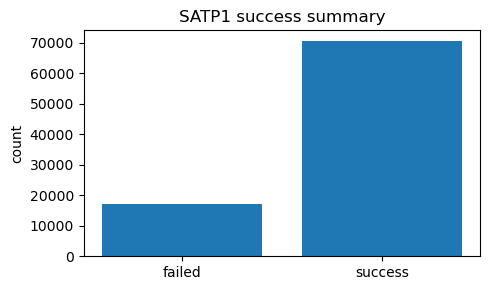

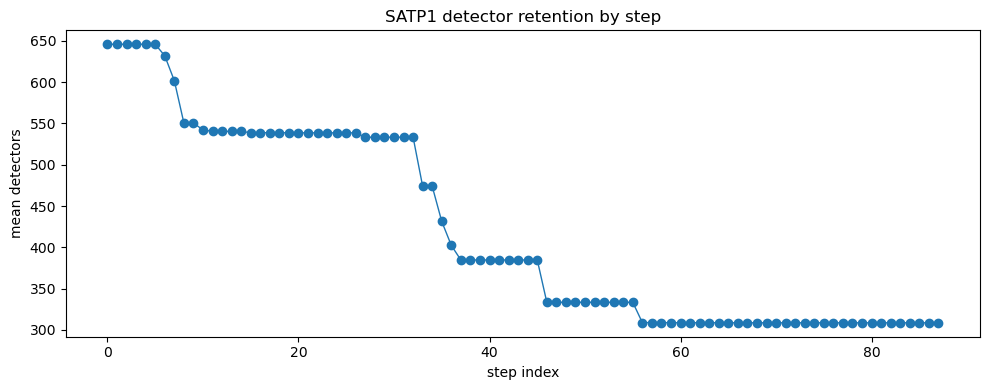

Artifacts directory ready: /home/ms3067/so_data_exploration/tiger/202601_v4/plots/analysis/satp1


In [7]:
output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

if bundle['success_summary']:
    fig, ax = plt.subplots(figsize=(5, 3))
    plot_rows = []
    for row in bundle['success_summary']:
        label = {1: 'success', 0: 'failed'}.get(row['success'], str(row['success']))
        plot_rows.append((label, row['count']))
    ax.bar([row[0] for row in plot_rows], [row[1] for row in plot_rows])
    ax.set_title(f"{config.telescope.upper()} success summary")
    ax.set_ylabel('count')
    fig.tight_layout()
    plt.show()
    # if config.save_artifacts:
    #     fig.savefig(output_dir / f'{config.telescope}_success_summary.png', dpi=150)

if bundle['retention_summary']:
    fig, ax = plt.subplots(figsize=(10, 4))
    retention_rows = bundle['retention_summary']
    ax.plot(
        [row['step_index'] for row in retention_rows],
        [row['mean_ndets'] for row in retention_rows],
        marker='o',
        linewidth=1,
    )
    ax.set_title(f"{config.telescope.upper()} detector retention by step")
    ax.set_xlabel('step index')
    ax.set_ylabel('mean detectors')
    fig.tight_layout()
    plt.show()
    # if config.save_artifacts:
    #     fig.savefig(output_dir / f'{config.telescope}_detector_retention.png', dpi=150)

if bundle['wafer_band_summary']:
    bundle['wafer_band_summary'][:20]
    if config.save_artifacts:
        with open(output_dir / f'{config.telescope}_wafer_band_summary.csv', 'w', encoding='utf-8', newline='') as handle:
            writer = csv.DictWriter(handle, fieldnames=list(bundle['wafer_band_summary'][0].keys()))
            writer.writeheader()
            writer.writerows(bundle['wafer_band_summary'])

hdf5_preview_rows = []
for inspection in bundle['hdf5_inspections']:
    hdf5_preview_rows.append({
        'path': inspection.path,
        'datasets': ', '.join(inspection.datasets),
        'n_obs_ids': inspection.n_obs_ids,
        'n_det_ids': inspection.n_det_ids,
    })

if hdf5_preview_rows:
    hdf5_preview_rows
    if config.save_artifacts:
        with open(output_dir / f'{config.telescope}_hdf5_inventory.csv', 'w', encoding='utf-8', newline='') as handle:
            writer = csv.DictWriter(handle, fieldnames=list(hdf5_preview_rows[0].keys()))
            writer.writeheader()
            writer.writerows(hdf5_preview_rows)

with open(output_dir / f'{config.telescope}_analysis_config.json', 'w', encoding='utf-8') as handle:
    json.dump(asdict(config), handle, indent=2)

print(f'Artifacts directory ready: {output_dir}')


## Open Questions And Next Decisions

Use this section to decide what should graduate from notebook exploration into the script.

Suggested next items:
- Which detector-step plots are most useful: mean retention, fractional retention, or per-wafer retention?
- Which wafer-band tables should be exported routinely?
- Do we want HDF5 plots at detector level, observation level, or both?
- Should the script emit only PNG and CSV, or also a compact markdown/html report?
- Which failure modes from the SQLite database should be summarized by default?

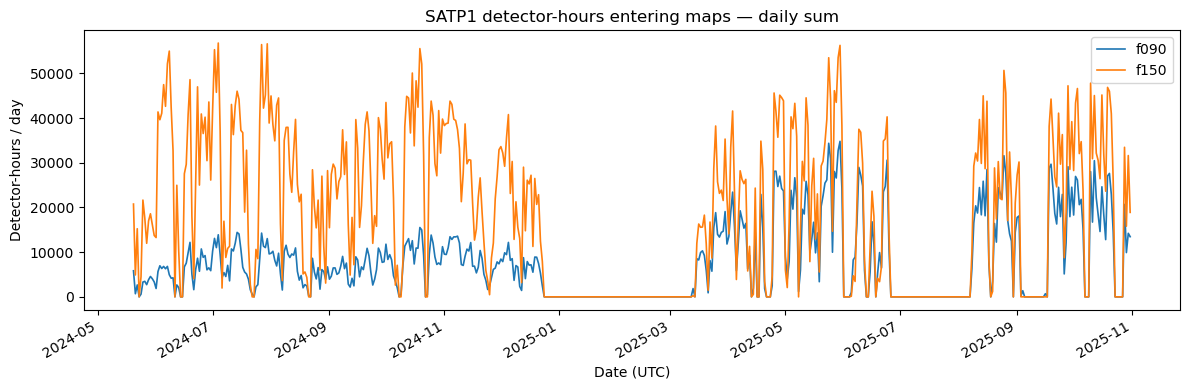

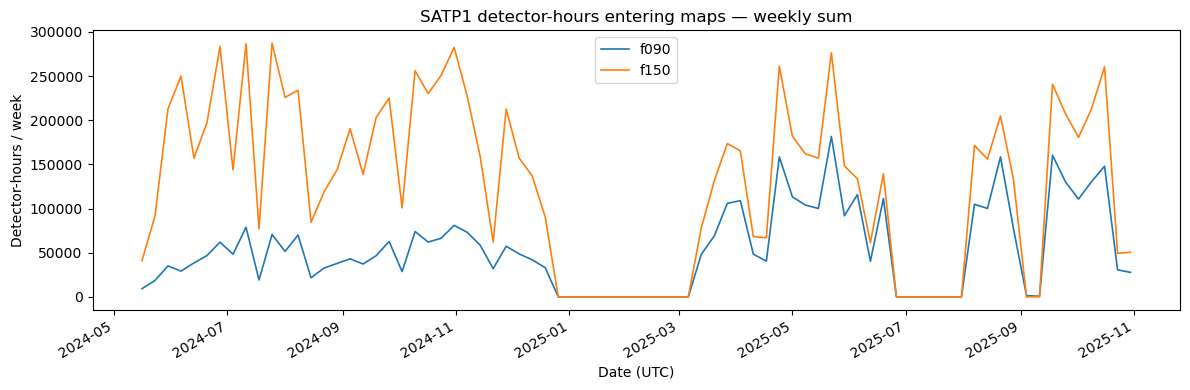

Final step column: det_87_noise_ndets
Bands: ['f090', 'f150']
  Total detector-hours (f090): 4131527.2
  Total detector-hours (f150): 9827162.0


In [8]:

import datetime
from collections import defaultdict

SAMPLE_RATE = 200  # Hz

success_rows = [row for row in bundle['obs_rows'] if row.get('success') == 1]

final_step = max(bundle['detector_steps'], key=lambda s: s['step_index'])
final_col = final_step['column']

def extract_obs_timestamp(obs_id: str) -> int | None:
    m = re.search(r'obs_(\d+)_', obs_id)
    return int(m.group(1)) if m else None

# ── aggregate: sum final ndets and estimate duration per (obs_id, band) ───────
# Duration = max(total_samples / det_0_starting_ndets) across wafers / sample_rate
agg: dict[tuple[str, str], dict] = defaultdict(lambda: {'n_dets': 0, 'timestamp': None, 'max_samples_per_det': 0.0})
for row in success_rows:
    obs_id = row['obs_id']
    band = row.get('band')
    if band is None:
        continue
    key = (obs_id, band)
    agg[key]['n_dets'] += row.get(final_col) or 0
    if agg[key]['timestamp'] is None:
        agg[key]['timestamp'] = extract_obs_timestamp(obs_id)
    det0 = row.get('det_0_starting_ndets') or 0
    if det0 > 0:
        spd = (row.get('total_samples') or 0) / det0
        agg[key]['max_samples_per_det'] = max(agg[key]['max_samples_per_det'], spd)

for info in agg.values():
    info['duration_h'] = info['max_samples_per_det'] / SAMPLE_RATE / 3600.0

_epoch = datetime.datetime(1970, 1, 1)
bands = sorted({row.get('band') for row in success_rows if row.get('band')})

# ── helper: bin (timestamp, det_hours) into fixed-width periods ───────────────
def bin_det_hours(series: list[tuple[int, float]], bin_seconds: int) -> tuple[list[datetime.datetime], list[float]]:
    if not series:
        return [], []
    t0 = min(ts for ts, _ in series) // bin_seconds * bin_seconds
    t1 = max(ts for ts, _ in series)
    n_bins = int((t1 - t0) // bin_seconds) + 1
    totals = np.zeros(n_bins)
    for ts, dh in series:
        totals[int((ts - t0) // bin_seconds)] += dh
    dates = [_epoch + datetime.timedelta(seconds=int(t0 + i * bin_seconds)) for i in range(n_bins)]
    return dates, totals.tolist()

# ── collect per-band (ts, det_hours) series ───────────────────────────────────
band_ts_dh: dict[str, list[tuple[int, float]]] = {b: [] for b in bands}
for (obs_id, band), info in agg.items():
    ts = info['timestamp']
    if ts is None:
        continue
    band_ts_dh[band].append((ts, info['n_dets'] * info['duration_h']))
for b in bands:
    band_ts_dh[b].sort()

# ── Plot 1: detector-hours per day ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
for band in bands:
    dates, totals = bin_det_hours(band_ts_dh[band], 86400)
    ax.plot(dates, totals, linewidth=1.2, label=band)
ax.set_xlabel('Date (UTC)')
ax.set_ylabel('Detector-hours / day')
ax.set_title(f"{config.telescope.upper()} detector-hours entering maps — daily sum")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# ── Plot 2: detector-hours per week ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
for band in bands:
    dates, totals = bin_det_hours(band_ts_dh[band], 7 * 86400)
    ax.plot(dates, totals, linewidth=1.2, label=band)
ax.set_xlabel('Date (UTC)')
ax.set_ylabel('Detector-hours / week')
ax.set_title(f"{config.telescope.upper()} detector-hours entering maps — weekly sum")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

print(f"Final step column: {final_col}")
print(f"Bands: {bands}")
for band in bands:
    total_det_hours = sum(dh for _, dh in band_ts_dh[band])
    print(f"  Total detector-hours ({band}): {total_det_hours:.1f}")


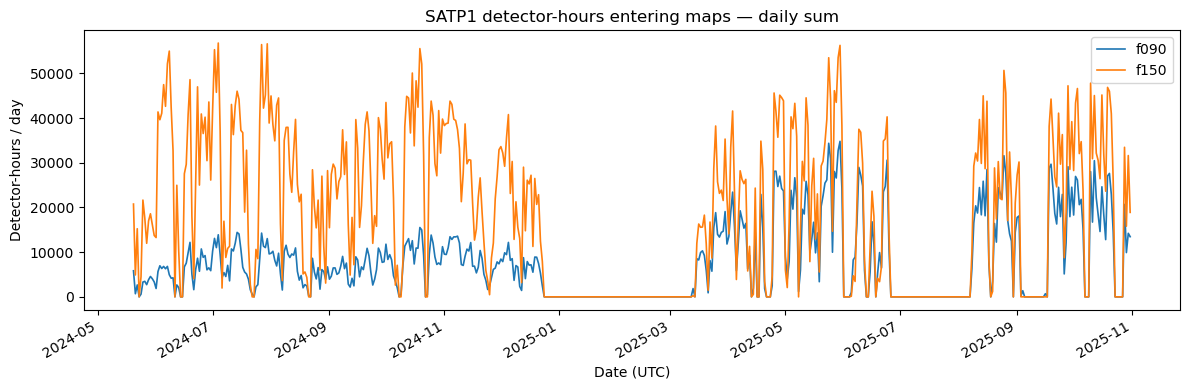

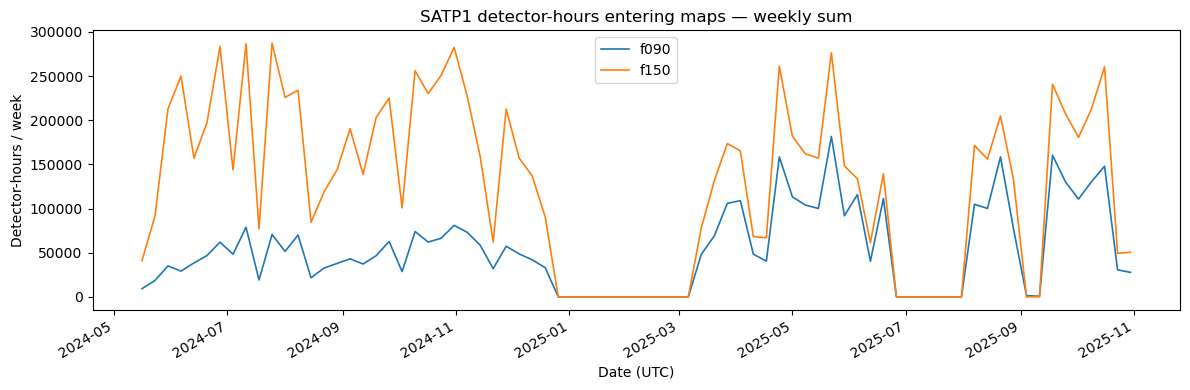

Final step column: det_87_noise_ndets
Bands: ['f090', 'f150']
  Total detector-hours (f090): 4131527.2
  Total detector-hours (f150): 9827162.0


In [9]:
import datetime
from collections import defaultdict

SAMPLE_RATE = 200  # Hz

success_rows = [row for row in bundle['obs_rows'] if row.get('success') == 1]

final_step = max(bundle['detector_steps'], key=lambda s: s['step_index'])
final_col = final_step['column']

def extract_obs_timestamp(obs_id: str) -> int | None:
    m = re.search(r'obs_(\d+)_', obs_id)
    return int(m.group(1)) if m else None

# ── aggregate: sum final ndets and estimate duration per (obs_id, band) ───────
# Duration = max(total_samples / det_0_starting_ndets) across wafers / sample_rate
agg: dict[tuple[str, str], dict] = defaultdict(lambda: {'n_dets': 0, 'timestamp': None, 'max_samples_per_det': 0.0})
for row in success_rows:
    obs_id = row['obs_id']
    band = row.get('band')
    if band is None:
        continue
    key = (obs_id, band)
    agg[key]['n_dets'] += row.get(final_col) or 0
    if agg[key]['timestamp'] is None:
        agg[key]['timestamp'] = extract_obs_timestamp(obs_id)
    det0 = row.get('det_0_starting_ndets') or 0
    if det0 > 0:
        spd = (row.get('total_samples') or 0) / det0
        agg[key]['max_samples_per_det'] = max(agg[key]['max_samples_per_det'], spd)

for info in agg.values():
    info['duration_h'] = info['max_samples_per_det'] / SAMPLE_RATE / 3600.0

_epoch = datetime.datetime(1970, 1, 1)
bands = sorted({row.get('band') for row in success_rows if row.get('band')})

# ── helper: bin (timestamp, det_hours) into fixed-width periods ───────────────
def bin_det_hours(series: list[tuple[int, float]], bin_seconds: int) -> tuple[list[datetime.datetime], list[float]]:
    if not series:
        return [], []
    t0 = min(ts for ts, _ in series) // bin_seconds * bin_seconds
    t1 = max(ts for ts, _ in series)
    n_bins = int((t1 - t0) // bin_seconds) + 1
    totals = np.zeros(n_bins)
    for ts, dh in series:
        totals[int((ts - t0) // bin_seconds)] += dh
    dates = [_epoch + datetime.timedelta(seconds=int(t0 + i * bin_seconds)) for i in range(n_bins)]
    return dates, totals.tolist()

# ── collect per-band (ts, det_hours) series ───────────────────────────────────
band_ts_dh: dict[str, list[tuple[int, float]]] = {b: [] for b in bands}
for (obs_id, band), info in agg.items():
    ts = info['timestamp']
    if ts is None:
        continue
    band_ts_dh[band].append((ts, info['n_dets'] * info['duration_h']))
for b in bands:
    band_ts_dh[b].sort()

# Ensure output directory exists
output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

# ── Plot 1: detector-hours per day ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
for band in bands:
    dates, totals = bin_det_hours(band_ts_dh[band], 86400)
    ax.plot(dates, totals, linewidth=1.2, label=band)
ax.set_xlabel('Date (UTC)')
ax.set_ylabel('Detector-hours / day')
ax.set_title(f"{config.telescope.upper()} detector-hours entering maps — daily sum")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_det_hours_daily.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: detector-hours per week ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
for band in bands:
    dates, totals = bin_det_hours(band_ts_dh[band], 7 * 86400)
    ax.plot(dates, totals, linewidth=1.2, label=band)
ax.set_xlabel('Date (UTC)')
ax.set_ylabel('Detector-hours / week')
ax.set_title(f"{config.telescope.upper()} detector-hours entering maps — weekly sum")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_det_hours_weekly.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Final step column: {final_col}")
print(f"Bands: {bands}")
for band in bands:
    total_det_hours = sum(dh for _, dh in band_ts_dh[band])
    print(f"  Total detector-hours ({band}): {total_det_hours:.1f}")


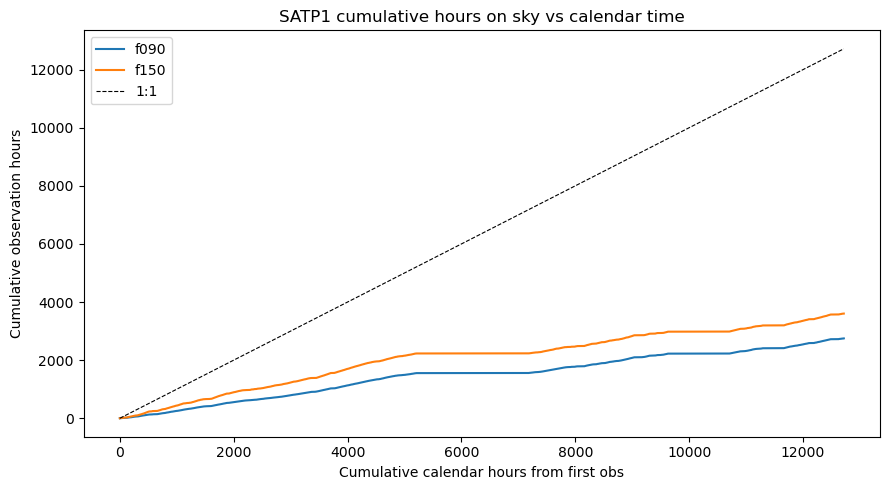

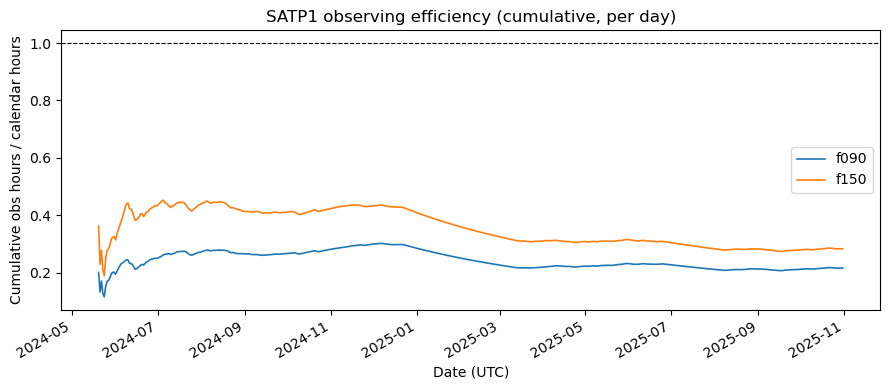

Calendar span: 1716177753 → 1761953072  (12715.4 h)
  f090: 2747.8 obs-h / 12715.4 cal-h  = 0.2161
  f150: 3602.7 obs-h / 12715.4 cal-h  = 0.2833


In [10]:

# An obs is counted once per band if ANY wafer has final-step ndets > 0
obs_band_success: dict[tuple[str, str], float] = {
    (obs_id, band): info['duration_h']
    for (obs_id, band), info in agg.items()
    if info['n_dets'] > 0
}

# ── per-band sorted series: (timestamp, duration_hours) ──────────────────────
band_obs: dict[str, list[tuple[int, float]]] = {b: [] for b in bands}
for (obs_id, band), dur in obs_band_success.items():
    ts = agg[(obs_id, band)]['timestamp']
    band_obs[band].append((ts, dur))
for b in bands:
    band_obs[b].sort()

t_start = min(ts for series in band_obs.values() for ts, _ in series)
t_end   = max(ts for series in band_obs.values() for ts, _ in series)
total_calendar_hours = (t_end - t_start) / 3600.0

# Ensure output directory exists
output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

# ── Plot 1: cumulative obs hours vs cumulative calendar hours ─────────────────
fig, ax = plt.subplots(figsize=(9, 5))
for b in bands:
    series = band_obs[b]
    cum_obs_h = np.cumsum([dur for _, dur in series])
    cum_cal_h = [(ts - t_start) / 3600.0 for ts, _ in series]
    ax.plot(cum_cal_h, cum_obs_h, linewidth=1.5, label=b)

ax.plot([0, total_calendar_hours], [0, total_calendar_hours], 'k--', linewidth=0.8, label='1:1')
ax.set_xlabel('Cumulative calendar hours from first obs')
ax.set_ylabel('Cumulative observation hours')
ax.set_title(f"{config.telescope.upper()} cumulative hours on sky vs calendar time")
ax.legend()
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_cumulative_hours.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: per-day efficiency (cumulative obs hours / calendar hours elapsed) ─
fig, ax = plt.subplots(figsize=(9, 4))
for b in bands:
    series = band_obs[b]
    day_start = t_start // 86400 * 86400
    days_elapsed = int((t_end - day_start) // 86400) + 1

    daily_obs_h = np.zeros(days_elapsed)
    for ts, dur in series:
        day_idx = int((ts - day_start) // 86400)
        if 0 <= day_idx < days_elapsed:
            daily_obs_h[day_idx] += dur

    cum_obs_h = np.cumsum(daily_obs_h)
    day_numbers = np.arange(days_elapsed)
    cum_cal_h = (day_numbers + 1) * 24.0
    efficiency = cum_obs_h / cum_cal_h

    day_dates = [_epoch + datetime.timedelta(seconds=int(day_start + d * 86400)) for d in day_numbers]
    ax.plot(day_dates, efficiency, linewidth=1.2, label=b)

ax.axhline(1.0, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel('Date (UTC)')
ax.set_ylabel('Cumulative obs hours / calendar hours')
ax.set_title(f"{config.telescope.upper()} observing efficiency (cumulative, per day)")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary ratio ─────────────────────────────────────────────────────────────
print(f"Calendar span: {t_start} → {t_end}  ({total_calendar_hours:.1f} h)")
for b in bands:
    total_obs_h = sum(dur for _, dur in band_obs[b])
    print(f"  {b}: {total_obs_h:.1f} obs-h / {total_calendar_hours:.1f} cal-h  = {total_obs_h / total_calendar_hours:.4f}")


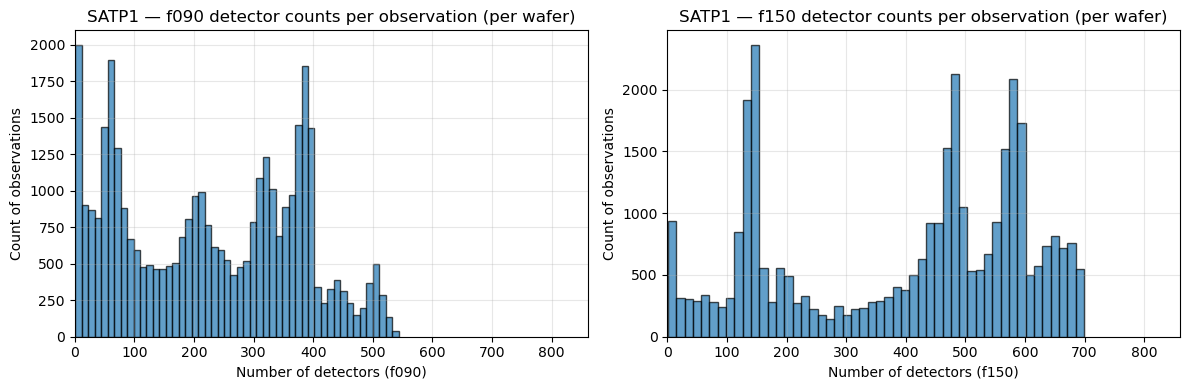

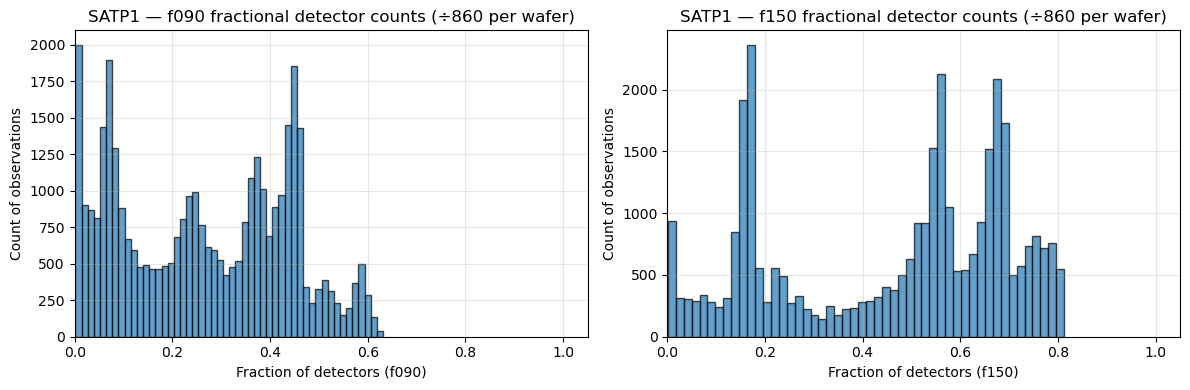

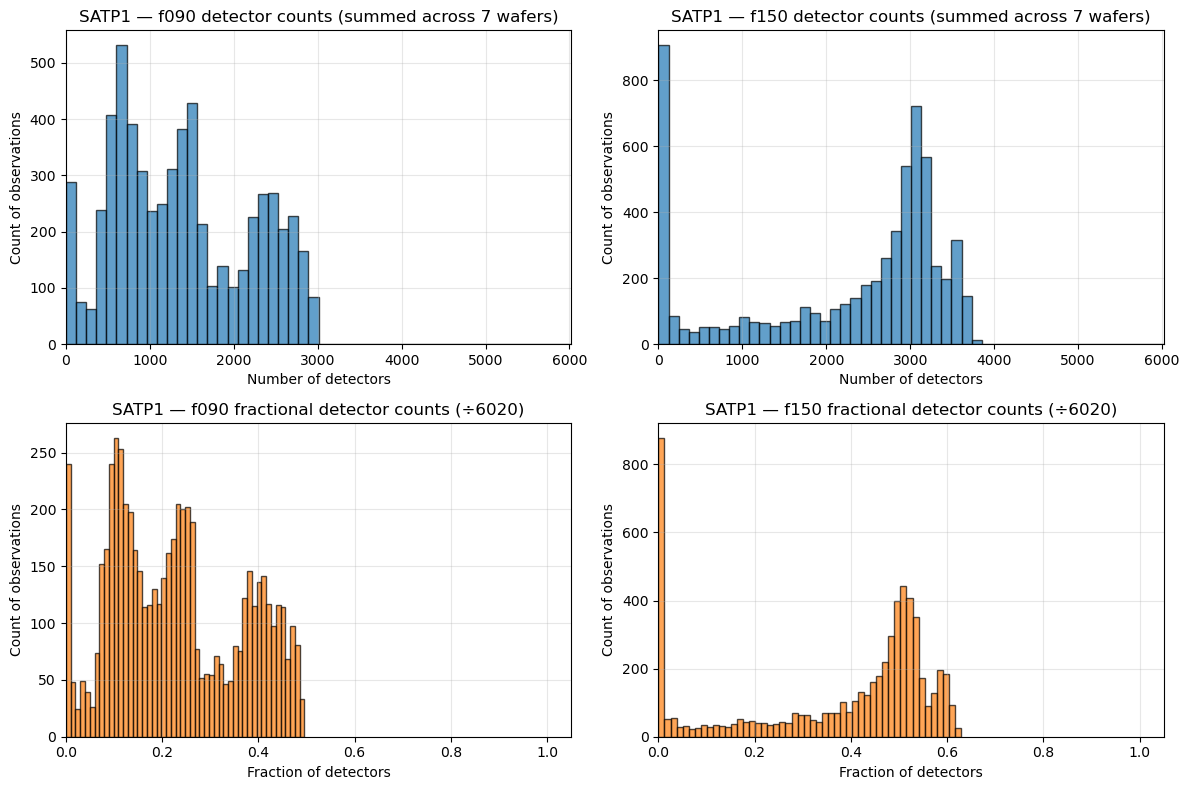

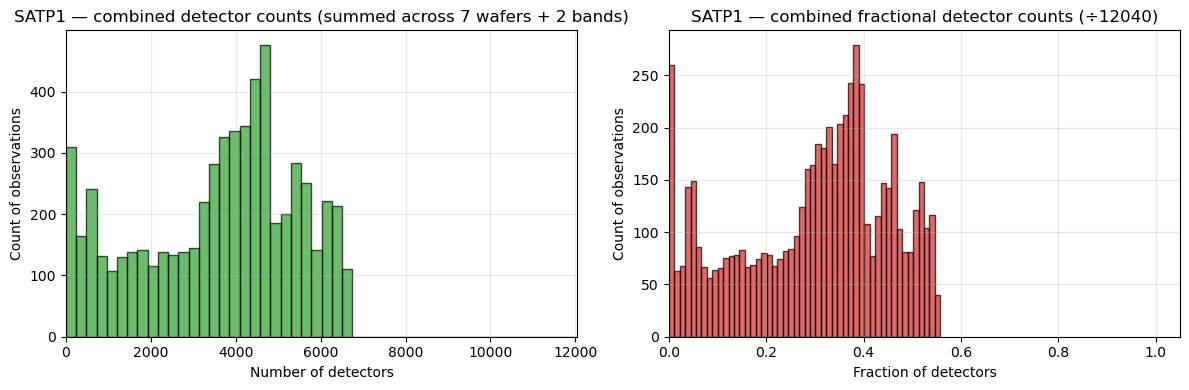


SUMMARY STATISTICS FOR SATP1

1. CUMULATIVE DETECTOR-HOURS:
   f090:          4,131,527.2 det-hours
   f150:          9,827,162.0 det-hours
   Combined:     13,958,689.2 det-hours

2. POSSIBLE DETECTOR-HOURS (max if all 100% available):
   f090:         76,546,505.7 det-hours
   f150:         76,546,505.7 det-hours
   Combined:    153,093,011.3 det-hours

3. CUMULATIVE CALENDAR HOURS:
                  12,715.4 hours

4. CUMULATIVE OBSERVATION HOURS (ignoring detector count):
   f090:              2,747.8 hours
   f150:              3,602.7 hours
   Combined:          6,350.5 hours

5. DETECTOR FRACTION STATISTICS (relative to max possible):
   f090:      avg=0.2284, max=0.4957, median=0.2153
   f150:      avg=0.3705, max=0.6287, median=0.4640
   Combined:  avg=0.2995, max=0.5576, median=0.3292

✓ Statistics saved to: /home/ms3067/so_data_exploration/tiger/202601_v4/plots/analysis/satp1/satp1_statistics.csv
✓ Plots saved to /home/ms3067/so_data_exploration/tiger/202601_v4/plots/analys

In [11]:
# ──────────────────────────────────────────────────────────────────────────────
# Comprehensive detector statistics and histograms
# ──────────────────────────────────────────────────────────────────────────────

import pandas as pd

# Ensure output directory exists
output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

# Constants: max detectors per wafer-band combo and per band total
DETECTORS_PER_WAFER_PER_BAND = 860
MAX_DETECTORS_PER_BAND = 6020  # 860 × 7 wafers
MAX_DETECTORS_TOTAL = 12040    # 2 bands × 6020

# ── Extract detector counts per observation per wafer per band ────────────────
# From success_rows: each row is one wafer in one observation
det_counts_by_band: dict[str, list[int]] = {b: [] for b in bands}
det_counts_by_wafer_band: dict[tuple[str, str], list[int]] = {}  # (band, wafer) -> [counts]
det_counts_combined: list[int] = []  # combined across all wafers

for row in success_rows:
    band = row.get('band')
    wafer = row.get('wafer')
    if band is None or wafer is None:
        continue

    det_count = row.get(final_col) or 0
    det_counts_by_band[band].append(det_count)

    key = (band, wafer)
    if key not in det_counts_by_wafer_band:
        det_counts_by_wafer_band[key] = []
    det_counts_by_wafer_band[key].append(det_count)

# ── Sum detector counts across all wafers for each observation-band ──────────
# Use observation timestamp as the grouping key so all wafers for one obs are summed together.
obs_to_det_counts: dict[int, dict[str, int]] = {}
for row in success_rows:
    obs_id = row.get('obs_id')
    band = row.get('band')
    if obs_id is None or band is None:
        continue

    ts = extract_obs_timestamp(obs_id)
    if ts is None:
        continue

    if ts not in obs_to_det_counts:
        obs_to_det_counts[ts] = {b: 0 for b in bands}
    obs_to_det_counts[ts][band] += row.get(final_col) or 0

# Combined across all wafers per observation-band (summed across wafers)
det_counts_all_wafers_by_band: dict[str, list[int]] = {b: [] for b in bands}
det_counts_all_wafers_combined: list[int] = []  # summed across all wafers and bands per obs

for ts, band_dets in obs_to_det_counts.items():
    for band in bands:
        det_counts_all_wafers_by_band[band].append(band_dets[band])
    det_counts_all_wafers_combined.append(sum(band_dets.values()))

# ── Plot 1: Histogram of detector counts per wafer-band ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for idx, band in enumerate(bands):
    ax = axes[idx]
    ax.hist(det_counts_by_band[band], bins=50, edgecolor='black', alpha=0.7)
    ax.set_xlabel(f'Number of detectors ({band})')
    ax.set_ylabel('Count of observations')
    ax.set_title(f"{config.telescope.upper()} — {band} detector counts per observation (per wafer)")
    ax.set_xlim(0, DETECTORS_PER_WAFER_PER_BAND)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_det_counts_per_wafer_band.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: Histogram of fractional detector counts per wafer-band ────────────
fractional_counts_by_band = {b: [c / DETECTORS_PER_WAFER_PER_BAND for c in det_counts_by_band[b]] for b in bands}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for idx, band in enumerate(bands):
    ax = axes[idx]
    ax.hist(fractional_counts_by_band[band], bins=50, edgecolor='black', alpha=0.7)
    ax.set_xlabel(f'Fraction of detectors ({band})')
    ax.set_ylabel('Count of observations')
    ax.set_title(f"{config.telescope.upper()} — {band} fractional detector counts (÷860 per wafer)")
    ax.set_xlim(0, 1.05)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_det_fractions_per_wafer_band.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: Histograms split by band (combined across all wafers) ────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
# Top row: detector counts (summed across all 7 wafers)
for idx, band in enumerate(bands):
    ax = axes[0, idx]
    ax.hist(
        det_counts_all_wafers_by_band[band],
        bins=50,
        range=(0, MAX_DETECTORS_PER_BAND),
        edgecolor='black',
        alpha=0.7,
        color='C0',
    )
    ax.set_xlabel('Number of detectors')
    ax.set_ylabel('Count of observations')
    ax.set_title(f"{config.telescope.upper()} — {band} detector counts (summed across 7 wafers)")
    ax.set_xlim(0, MAX_DETECTORS_PER_BAND)
    ax.grid(True, alpha=0.3)
# Bottom row: fractional counts (relative to 6020 = 860×7)
for idx, band in enumerate(bands):
    ax = axes[1, idx]
    fractional_per_band = [c / MAX_DETECTORS_PER_BAND for c in det_counts_all_wafers_by_band[band]]
    ax.hist(fractional_per_band, bins=50, edgecolor='black', alpha=0.7, color='C1')
    ax.set_xlabel('Fraction of detectors')
    ax.set_ylabel('Count of observations')
    ax.set_title(f"{config.telescope.upper()} — {band} fractional detector counts (÷6020)")
    ax.set_xlim(0, 1.05)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_det_histograms_by_band.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 4: Combined histograms across both bands ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Detector counts (summed across all 7 wafers and both bands)
ax = axes[0]
ax.hist(
    det_counts_all_wafers_combined,
    bins=50,
    range=(0, MAX_DETECTORS_TOTAL),
    edgecolor='black',
    alpha=0.7,
    color='C2',
)
ax.set_xlabel('Number of detectors')
ax.set_ylabel('Count of observations')
ax.set_title(f"{config.telescope.upper()} — combined detector counts (summed across 7 wafers + 2 bands)")
ax.set_xlim(0, MAX_DETECTORS_TOTAL)
ax.grid(True, alpha=0.3)
# Fractional counts (relative to 12040 = 860×7×2)
ax = axes[1]
fractional_combined = [c / MAX_DETECTORS_TOTAL for c in det_counts_all_wafers_combined]
ax.hist(fractional_combined, bins=50, edgecolor='black', alpha=0.7, color='C3')
ax.set_xlabel('Fraction of detectors')
ax.set_ylabel('Count of observations')
ax.set_title(f"{config.telescope.upper()} — combined fractional detector counts (÷12040)")
ax.set_xlim(0, 1.05)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.savefig(output_dir / f'{config.telescope}_det_histograms_combined.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Compute summary statistics ────────────────────────────────────────────────
stats = {}

# 1. Total cumulative detector-hours per band and combined (from agg data)
# Recalculate from agg which has n_dets (summed across wafers) × duration_h
det_hours_by_band: dict[str, float] = {b: 0.0 for b in bands}
for (obs_id, band), info in agg.items():
    if band in bands and info['n_dets'] > 0:
        det_hours_by_band[band] += info['n_dets'] * info['duration_h']

stats['det_hours_f090'] = det_hours_by_band.get('f090', 0.0)
stats['det_hours_f150'] = det_hours_by_band.get('f150', 0.0)
stats['det_hours_combined'] = stats['det_hours_f090'] + stats['det_hours_f150']

# 2. Total possible detector-hours
stats['possible_det_hours_f090'] = total_calendar_hours * MAX_DETECTORS_PER_BAND
stats['possible_det_hours_f150'] = total_calendar_hours * MAX_DETECTORS_PER_BAND
stats['possible_det_hours_combined'] = total_calendar_hours * MAX_DETECTORS_TOTAL

# 3. Total cumulative calendar hours
stats['calendar_hours'] = total_calendar_hours

# 4. Total cumulative observation hours (ignoring detector count)
stats['obs_hours_f090'] = sum(dur for _, dur in band_obs['f090'])
stats['obs_hours_f150'] = sum(dur for _, dur in band_obs['f150'])
stats['obs_hours_combined'] = stats['obs_hours_f090'] + stats['obs_hours_f150']

# 5. Average, max, median fraction of detectors per band and combined
det_fractions_f090 = np.array([c / MAX_DETECTORS_PER_BAND for c in det_counts_all_wafers_by_band['f090']])
det_fractions_f150 = np.array([c / MAX_DETECTORS_PER_BAND for c in det_counts_all_wafers_by_band['f150']])
det_fractions_combined = np.array(fractional_combined)

stats['avg_frac_f090'] = np.mean(det_fractions_f090)
stats['max_frac_f090'] = np.max(det_fractions_f090)
stats['median_frac_f090'] = np.median(det_fractions_f090)

stats['avg_frac_f150'] = np.mean(det_fractions_f150)
stats['max_frac_f150'] = np.max(det_fractions_f150)
stats['median_frac_f150'] = np.median(det_fractions_f150)

stats['avg_frac_combined'] = np.mean(det_fractions_combined)
stats['max_frac_combined'] = np.max(det_fractions_combined)
stats['median_frac_combined'] = np.median(det_fractions_combined)

# Print summary
print(f"\n{'='*70}")
print(f"SUMMARY STATISTICS FOR {config.telescope.upper()}")
print(f"{'='*70}")
print(f"\n1. CUMULATIVE DETECTOR-HOURS:")
print(f"   f090:      {stats['det_hours_f090']:>15,.1f} det-hours")
print(f"   f150:      {stats['det_hours_f150']:>15,.1f} det-hours")
print(f"   Combined:  {stats['det_hours_combined']:>15,.1f} det-hours")

print(f"\n2. POSSIBLE DETECTOR-HOURS (max if all 100% available):")
print(f"   f090:      {stats['possible_det_hours_f090']:>15,.1f} det-hours")
print(f"   f150:      {stats['possible_det_hours_f150']:>15,.1f} det-hours")
print(f"   Combined:  {stats['possible_det_hours_combined']:>15,.1f} det-hours")

print(f"\n3. CUMULATIVE CALENDAR HOURS:")
print(f"   {stats['calendar_hours']:>23,.1f} hours")

print(f"\n4. CUMULATIVE OBSERVATION HOURS (ignoring detector count):")
print(f"   f090:      {stats['obs_hours_f090']:>15,.1f} hours")
print(f"   f150:      {stats['obs_hours_f150']:>15,.1f} hours")
print(f"   Combined:  {stats['obs_hours_combined']:>15,.1f} hours")

print(f"\n5. DETECTOR FRACTION STATISTICS (relative to max possible):")
print(f"   f090:      avg={stats['avg_frac_f090']:.4f}, max={stats['max_frac_f090']:.4f}, median={stats['median_frac_f090']:.4f}")
print(f"   f150:      avg={stats['avg_frac_f150']:.4f}, max={stats['max_frac_f150']:.4f}, median={stats['median_frac_f150']:.4f}")
print(f"   Combined:  avg={stats['avg_frac_combined']:.4f}, max={stats['max_frac_combined']:.4f}, median={stats['median_frac_combined']:.4f}")

# Save statistics to CSV
stats_df = pd.DataFrame([{
    'telescope': config.telescope,
    'det_hours_f090': stats['det_hours_f090'],
    'det_hours_f150': stats['det_hours_f150'],
    'det_hours_combined': stats['det_hours_combined'],
    'possible_det_hours_f090': stats['possible_det_hours_f090'],
    'possible_det_hours_f150': stats['possible_det_hours_f150'],
    'possible_det_hours_combined': stats['possible_det_hours_combined'],
    'calendar_hours': stats['calendar_hours'],
    'obs_hours_f090': stats['obs_hours_f090'],
    'obs_hours_f150': stats['obs_hours_f150'],
    'obs_hours_combined': stats['obs_hours_combined'],
    'avg_frac_f090': stats['avg_frac_f090'],
    'max_frac_f090': stats['max_frac_f090'],
    'median_frac_f090': stats['median_frac_f090'],
    'avg_frac_f150': stats['avg_frac_f150'],
    'max_frac_f150': stats['max_frac_f150'],
    'median_frac_f150': stats['median_frac_f150'],
    'avg_frac_combined': stats['avg_frac_combined'],
    'max_frac_combined': stats['max_frac_combined'],
    'median_frac_combined': stats['median_frac_combined'],
}])

stats_df.to_csv(output_dir / f'{config.telescope}_statistics.csv', index=False)
print(f"\n✓ Statistics saved to: {output_dir}/{config.telescope}_statistics.csv")
print(f"✓ Plots saved to {output_dir}/")

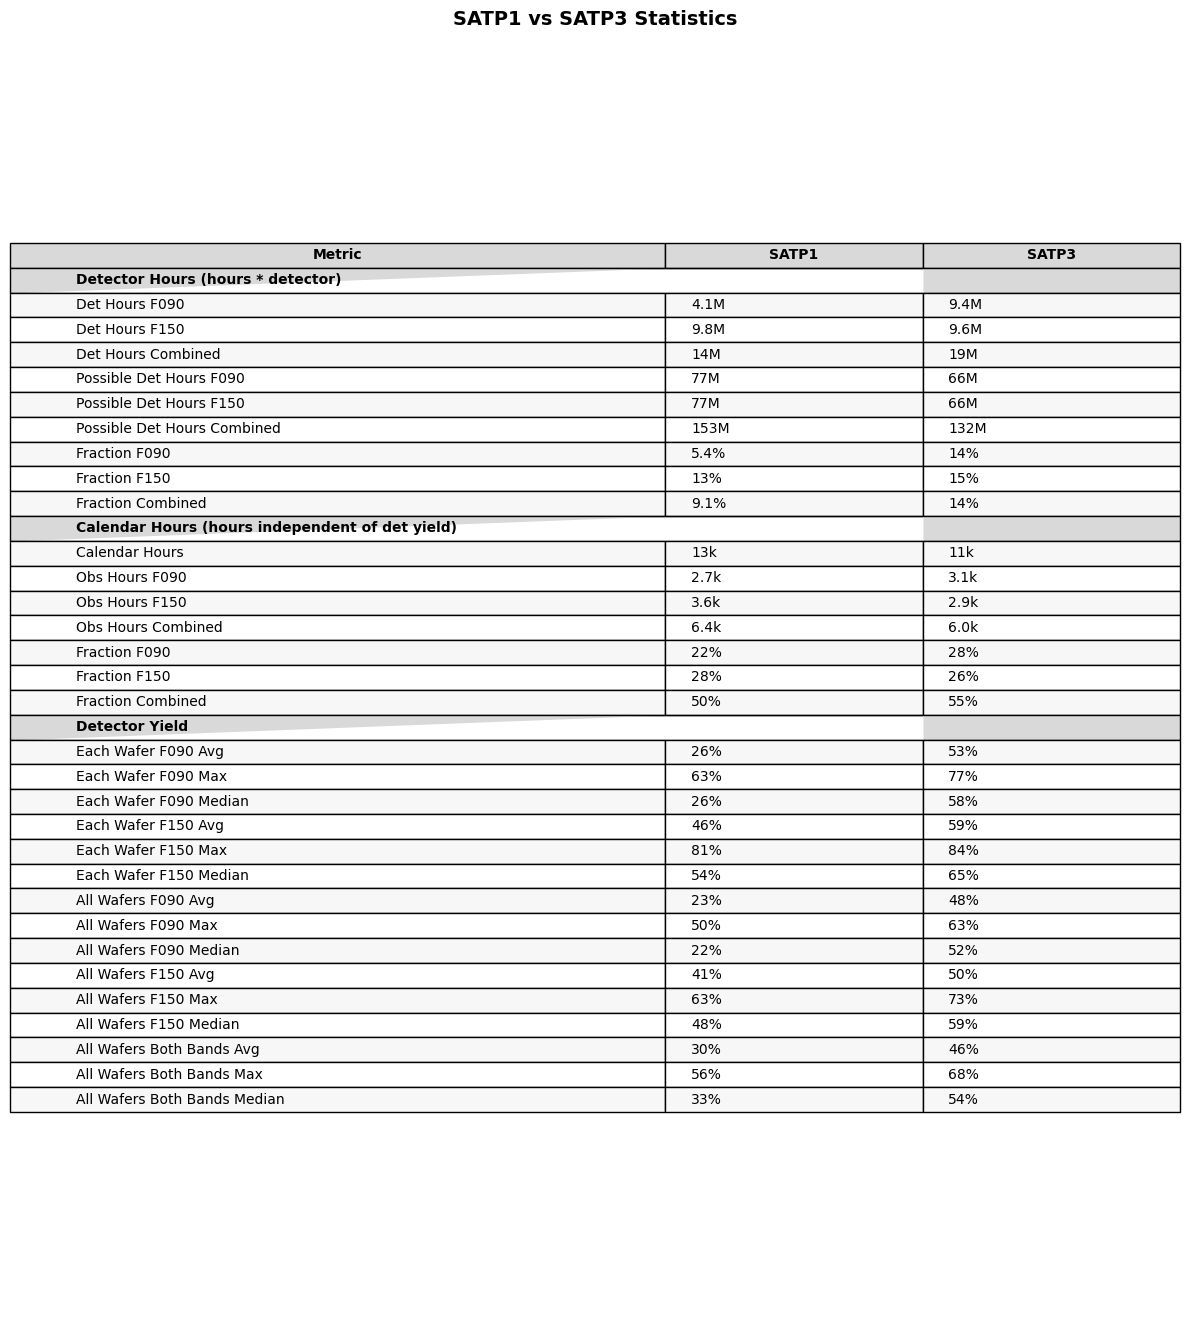

Saved combined table PNG: /home/ms3067/so_data_exploration/tiger/202601_v4/plots/analysis/satp1_satp3_statistics_table.png
Saved combined table PDF: /home/ms3067/so_data_exploration/tiger/202601_v4/plots/analysis/satp1_satp3_statistics_table.pdf


In [12]:
# Render a combined SATP1/SATP3 statistics table with 3 sections and export to PNG/PDF.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import sqlite3
import re
from collections import defaultdict

DETECTORS_PER_WAFER_PER_BAND = 860
MAX_DETECTORS_PER_BAND = 6020
MAX_DETECTORS_TOTAL = 12040


def fmt_fixed_sig(value: float, sig_figs: int = 2) -> str:
    if value == 0:
        return '0'
    magnitude = math.floor(math.log10(abs(value)))
    decimals = max(0, sig_figs - 1 - magnitude)
    return f"{value:.{decimals}f}"


def fmt_value(metric_name: str, value: object) -> str:
    if isinstance(value, (int, float, np.integer, np.floating)):
        v = float(value)
        if np.isnan(v):
            return 'nan'

        if 'frac' in metric_name.lower():
            return f"{fmt_fixed_sig(v * 100.0, 2)}%"

        av = abs(v)
        if av >= 1_000_000:
            return f"{fmt_fixed_sig(v / 1_000_000.0, 2)}M"
        if av >= 1_000:
            return f"{fmt_fixed_sig(v / 1_000.0, 2)}k"
        return fmt_fixed_sig(v, 2)

    return str(value)


def safe_div(num: float, den: float) -> float:
    if den == 0:
        return float('nan')
    return num / den


def extract_obs_timestamp(obs_id: str) -> int | None:
    m = re.search(r'obs_(\d+)_', obs_id)
    return int(m.group(1)) if m else None


def load_stats_row(csv_path: Path) -> dict[str, object]:
    df = pd.read_csv(csv_path)
    if df.empty:
        raise ValueError(f'No rows found in {csv_path}')
    return df.iloc[0].to_dict()


def compute_yield_stats(sqlite_path: Path) -> dict[str, float]:
    with sqlite3.connect(sqlite_path) as conn:
        conn.row_factory = sqlite3.Row
        cols = [r['name'] for r in conn.execute('PRAGMA table_info(obs)').fetchall()]
        det_cols = [c for c in cols if re.match(r'^det_\d+_.+_ndets$', c)]
        if not det_cols:
            raise ValueError(f'No detector columns found in {sqlite_path}')

        final_col = max(det_cols, key=lambda c: int(re.match(r'^det_(\d+)_', c).group(1)))
        rows = conn.execute(
            f"SELECT obs_id, band, success, {final_col} AS final_ndets FROM obs"
        ).fetchall()

    each_wafer: dict[str, list[float]] = {'f090': [], 'f150': []}
    obs_band_sum: dict[tuple[int, str], float] = defaultdict(float)

    for row in rows:
        if row['success'] != 1:
            continue
        band = row['band']
        if band not in ('f090', 'f150'):
            continue

        nd = float(row['final_ndets'] or 0)
        each_wafer[band].append(nd / DETECTORS_PER_WAFER_PER_BAND)

        ts = extract_obs_timestamp(row['obs_id'])
        if ts is not None:
            obs_band_sum[(ts, band)] += nd

    all_wafers_f090 = [v / MAX_DETECTORS_PER_BAND for (ts, b), v in obs_band_sum.items() if b == 'f090']
    all_wafers_f150 = [v / MAX_DETECTORS_PER_BAND for (ts, b), v in obs_band_sum.items() if b == 'f150']

    by_ts: dict[int, float] = defaultdict(float)
    for (ts, b), v in obs_band_sum.items():
        by_ts[ts] += v
    all_wafers_both = [v / MAX_DETECTORS_TOTAL for v in by_ts.values()]

    def s(values: list[float]) -> tuple[float, float, float]:
        if not values:
            return float('nan'), float('nan'), float('nan')
        arr = np.array(values, dtype=float)
        return float(np.mean(arr)), float(np.max(arr)), float(np.median(arr))

    ew90_avg, ew90_max, ew90_med = s(each_wafer['f090'])
    ew150_avg, ew150_max, ew150_med = s(each_wafer['f150'])
    aw90_avg, aw90_max, aw90_med = s(all_wafers_f090)
    aw150_avg, aw150_max, aw150_med = s(all_wafers_f150)
    awb_avg, awb_max, awb_med = s(all_wafers_both)

    return {
        'yield_each_wafer_f090_avg_frac': ew90_avg,
        'yield_each_wafer_f090_max_frac': ew90_max,
        'yield_each_wafer_f090_median_frac': ew90_med,
        'yield_each_wafer_f150_avg_frac': ew150_avg,
        'yield_each_wafer_f150_max_frac': ew150_max,
        'yield_each_wafer_f150_median_frac': ew150_med,
        'yield_all_wafers_f090_avg_frac': aw90_avg,
        'yield_all_wafers_f090_max_frac': aw90_max,
        'yield_all_wafers_f090_median_frac': aw90_med,
        'yield_all_wafers_f150_avg_frac': aw150_avg,
        'yield_all_wafers_f150_max_frac': aw150_max,
        'yield_all_wafers_f150_median_frac': aw150_med,
        'yield_all_wafers_both_bands_avg_frac': awb_avg,
        'yield_all_wafers_both_bands_max_frac': awb_max,
        'yield_all_wafers_both_bands_median_frac': awb_med,
    }


analysis_root = Path(DEFAULT_OUTPUT_ROOT)
satp1_csv = analysis_root / 'satp1' / 'satp1_statistics.csv'
satp3_csv = analysis_root / 'satp3' / 'satp3_statistics.csv'

if not satp1_csv.exists() or not satp3_csv.exists():
    raise FileNotFoundError(
        f'Missing stats CSVs. satp1 exists={satp1_csv.exists()}, satp3 exists={satp3_csv.exists()}'
    )

satp1_row = load_stats_row(satp1_csv)
satp3_row = load_stats_row(satp3_csv)

# Add requested section-level fractions.
for row in (satp1_row, satp3_row):
    row['dethr_frac_f090'] = safe_div(float(row.get('det_hours_f090', np.nan)), float(row.get('possible_det_hours_f090', np.nan)))
    row['dethr_frac_f150'] = safe_div(float(row.get('det_hours_f150', np.nan)), float(row.get('possible_det_hours_f150', np.nan)))
    row['dethr_frac_combined'] = safe_div(float(row.get('det_hours_combined', np.nan)), float(row.get('possible_det_hours_combined', np.nan)))

    row['cal_frac_f090'] = safe_div(float(row.get('obs_hours_f090', np.nan)), float(row.get('calendar_hours', np.nan)))
    row['cal_frac_f150'] = safe_div(float(row.get('obs_hours_f150', np.nan)), float(row.get('calendar_hours', np.nan)))
    row['cal_frac_combined'] = safe_div(float(row.get('obs_hours_combined', np.nan)), float(row.get('calendar_hours', np.nan)))

satp1_sqlite = Path('/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/databases/iso_v4_satp1_20260417.sqlite')
satp3_sqlite = Path('/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp3_20260417/databases/iso_v4_satp3_20260417.sqlite')

satp1_yield = compute_yield_stats(satp1_sqlite)
satp3_yield = compute_yield_stats(satp3_sqlite)


def build_rows() -> tuple[list[tuple[str, str, str]], set[int]]:
    rows: list[tuple[str, str, str]] = []
    section_header_rows: set[int] = set()

    def add_section(title: str) -> None:
        section_header_rows.add(len(rows) + 1)  # +1: table header is row 0
        rows.append((title, '', ''))

    def add_metric(label: str, key: str, left: dict[str, object], right: dict[str, object]) -> None:
        rows.append((label, fmt_value(key, left.get(key, np.nan)), fmt_value(key, right.get(key, np.nan))))

    add_section('Detector Hours (hours * detector)')
    add_metric('Det Hours F090', 'det_hours_f090', satp1_row, satp3_row)
    add_metric('Det Hours F150', 'det_hours_f150', satp1_row, satp3_row)
    add_metric('Det Hours Combined', 'det_hours_combined', satp1_row, satp3_row)
    add_metric('Possible Det Hours F090', 'possible_det_hours_f090', satp1_row, satp3_row)
    add_metric('Possible Det Hours F150', 'possible_det_hours_f150', satp1_row, satp3_row)
    add_metric('Possible Det Hours Combined', 'possible_det_hours_combined', satp1_row, satp3_row)
    add_metric('Fraction F090', 'dethr_frac_f090', satp1_row, satp3_row)
    add_metric('Fraction F150', 'dethr_frac_f150', satp1_row, satp3_row)
    add_metric('Fraction Combined', 'dethr_frac_combined', satp1_row, satp3_row)

    add_section('Calendar Hours (hours independent of det yield)')
    add_metric('Calendar Hours', 'calendar_hours', satp1_row, satp3_row)
    add_metric('Obs Hours F090', 'obs_hours_f090', satp1_row, satp3_row)
    add_metric('Obs Hours F150', 'obs_hours_f150', satp1_row, satp3_row)
    add_metric('Obs Hours Combined', 'obs_hours_combined', satp1_row, satp3_row)
    add_metric('Fraction F090', 'cal_frac_f090', satp1_row, satp3_row)
    add_metric('Fraction F150', 'cal_frac_f150', satp1_row, satp3_row)
    add_metric('Fraction Combined', 'cal_frac_combined', satp1_row, satp3_row)

    add_section('Detector Yield')
    add_metric('Each Wafer F090 Avg', 'yield_each_wafer_f090_avg_frac', satp1_yield, satp3_yield)
    add_metric('Each Wafer F090 Max', 'yield_each_wafer_f090_max_frac', satp1_yield, satp3_yield)
    add_metric('Each Wafer F090 Median', 'yield_each_wafer_f090_median_frac', satp1_yield, satp3_yield)
    add_metric('Each Wafer F150 Avg', 'yield_each_wafer_f150_avg_frac', satp1_yield, satp3_yield)
    add_metric('Each Wafer F150 Max', 'yield_each_wafer_f150_max_frac', satp1_yield, satp3_yield)
    add_metric('Each Wafer F150 Median', 'yield_each_wafer_f150_median_frac', satp1_yield, satp3_yield)

    add_metric('All Wafers F090 Avg', 'yield_all_wafers_f090_avg_frac', satp1_yield, satp3_yield)
    add_metric('All Wafers F090 Max', 'yield_all_wafers_f090_max_frac', satp1_yield, satp3_yield)
    add_metric('All Wafers F090 Median', 'yield_all_wafers_f090_median_frac', satp1_yield, satp3_yield)
    add_metric('All Wafers F150 Avg', 'yield_all_wafers_f150_avg_frac', satp1_yield, satp3_yield)
    add_metric('All Wafers F150 Max', 'yield_all_wafers_f150_max_frac', satp1_yield, satp3_yield)
    add_metric('All Wafers F150 Median', 'yield_all_wafers_f150_median_frac', satp1_yield, satp3_yield)

    add_metric('All Wafers Both Bands Avg', 'yield_all_wafers_both_bands_avg_frac', satp1_yield, satp3_yield)
    add_metric('All Wafers Both Bands Max', 'yield_all_wafers_both_bands_max_frac', satp1_yield, satp3_yield)
    add_metric('All Wafers Both Bands Median', 'yield_all_wafers_both_bands_median_frac', satp1_yield, satp3_yield)

    return rows, section_header_rows


rows, section_header_rows = build_rows()
fig_h = max(8.5, 0.34 * len(rows) + 1.8)
fig, ax = plt.subplots(figsize=(12, fig_h))
ax.axis('off')
ax.set_title('SATP1 vs SATP3 Statistics', fontsize=14, fontweight='bold', pad=10)

table = ax.table(
    cellText=rows,
    colLabels=['Metric', 'SATP1', 'SATP3'],
    colWidths=[0.56, 0.22, 0.22],
    loc='center',
    cellLoc='left',
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.2)

for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#d9d9d9')
        continue

    if r in section_header_rows:
        cell.set_facecolor('#d9d9d9')
        if c == 0:
            cell.set_text_props(weight='bold')
            cell.visible_edges = 'BTL'
        elif c == 1:
            cell.get_text().set_text('')
            cell.visible_edges = 'BT'
        elif c == 2:
            cell.get_text().set_text('')
            cell.visible_edges = 'BTR'
    elif r % 2 == 0:
        cell.set_facecolor('#f7f7f7')

fig.tight_layout()
combined_png = analysis_root / 'satp1_satp3_statistics_table.png'
combined_pdf = analysis_root / 'satp1_satp3_statistics_table.pdf'
fig.savefig(combined_png, dpi=220, bbox_inches='tight')
fig.savefig(combined_pdf, bbox_inches='tight')
plt.show()

print(f'Saved combined table PNG: {combined_png}')
print(f'Saved combined table PDF: {combined_pdf}')

/tmp/ipykernel_3897819/1881488716.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = plt.cm.get_cmap('tab10', max(len(wafer_names), 1))


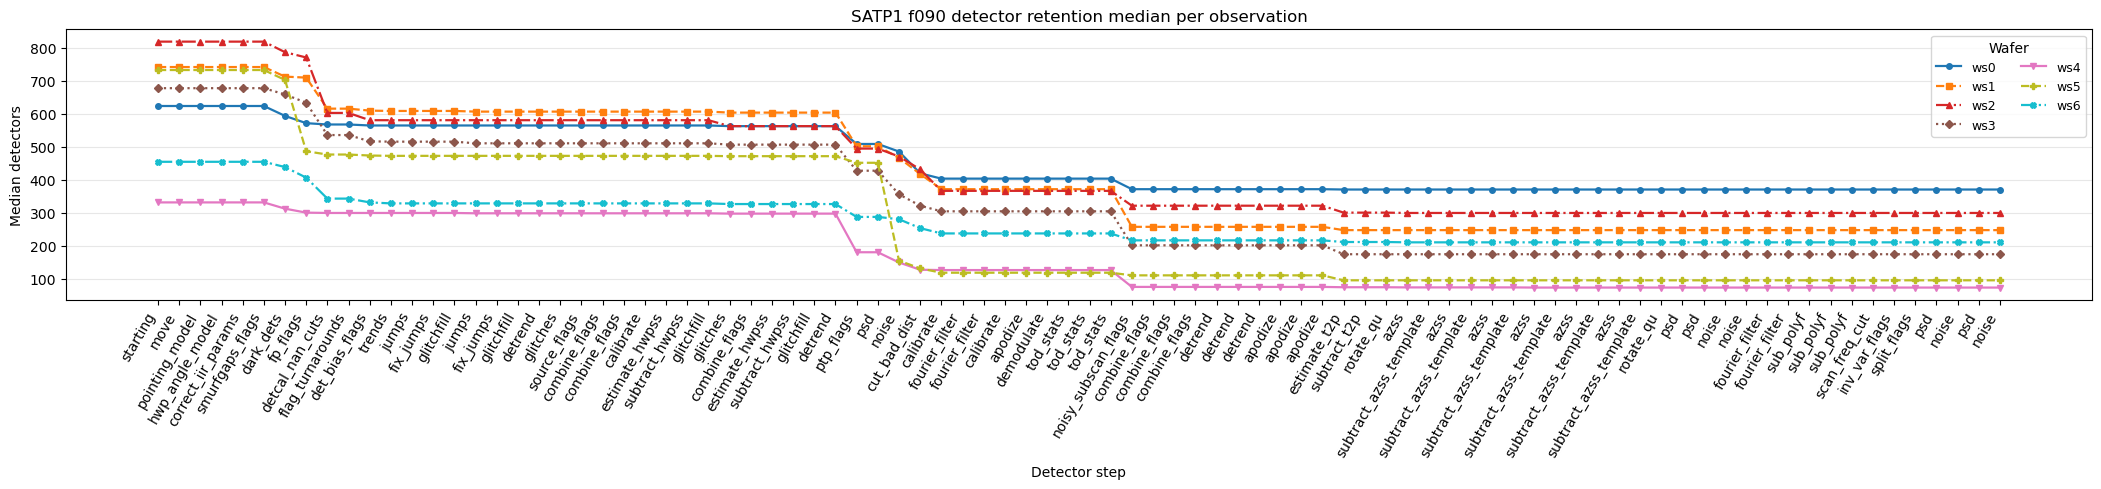

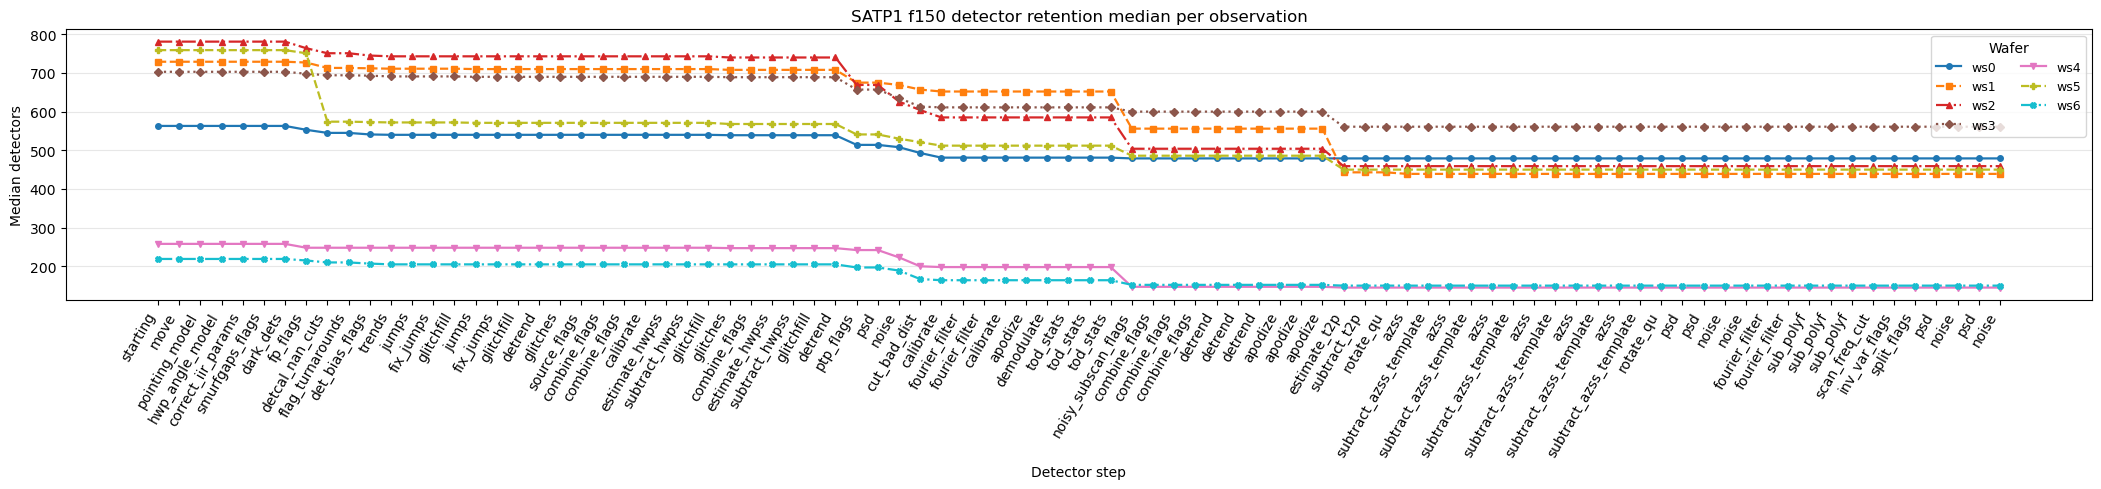

Rendered median retention curves for 2 bands.


In [14]:
# Per-band detector-step median retention curves with all wafers overlaid.

retention_plot_rows = [row for row in bundle['obs_rows'] if row.get('success') == 1]
step_info = bundle['detector_steps']
step_labels = [step['step_name'] for step in step_info]
step_columns = [step['column'] for step in step_info]

output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

wafer_band_keys = sorted({
    (row.get('wafer'), row.get('band'))
    for row in retention_plot_rows
    if row.get('wafer') is not None and row.get('band') is not None
})

bands_in_data = sorted({band for _, band in wafer_band_keys})
wafer_names = sorted({wafer for wafer, _ in wafer_band_keys})
line_styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
color_map = plt.cm.get_cmap('tab10', max(len(wafer_names), 1))
wafer_styles = {
    wafer: {
        'color': color_map(index % 10),
        'linestyle': line_styles[index % len(line_styles)],
        'marker': markers[index % len(markers)],
    }
    for index, wafer in enumerate(wafer_names)
}

rendered_bands = 0
for band in bands_in_data:
    fig_w = max(12, 0.24 * len(step_labels))
    fig, ax = plt.subplots(figsize=(fig_w, 5))
    plotted_any = False

    for wafer in wafer_names:
        wafer_rows = [
            row for row in retention_plot_rows
            if row.get('wafer') == wafer and row.get('band') == band
        ]
        if not wafer_rows:
            continue

        median_values = []
        valid_positions = []
        valid_labels = []
        for idx, (step_label, step_col) in enumerate(zip(step_labels, step_columns), start=1):
            values = [
                float(row[step_col])
                for row in wafer_rows
                if row.get(step_col) is not None and not np.isnan(float(row[step_col]))
            ]
            if values:
                median_values.append(float(np.median(values)))
                valid_positions.append(idx)
                valid_labels.append(step_label)

        if not median_values:
            continue

        style = wafer_styles[wafer]
        ax.plot(
            valid_positions,
            median_values,
            label=str(wafer),
            color=style['color'],
            linestyle=style['linestyle'],
            marker=style['marker'],
            linewidth=1.6,
            markersize=4,
        )
        plotted_any = True

    if not plotted_any:
        plt.close(fig)
        continue

    ax.set_xticks(range(1, len(step_labels) + 1))
    ax.set_xticklabels(step_labels, rotation=60, ha='right')
    ax.set_ylabel('Median detectors')
    ax.set_xlabel('Detector step')
    ax.set_title(f"{config.telescope.upper()} {band} detector retention median per observation")
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend(title='Wafer', ncol=2, fontsize=9)
    fig.tight_layout()
    fig.savefig(
        output_dir / f'{config.telescope}_{band}_retention_median_by_wafer.png',
        dpi=150,
        bbox_inches='tight',
    )
    plt.show()
    rendered_bands += 1

print(f'Rendered median retention curves for {rendered_bands} bands.')

/tmp/ipykernel_3897819/3857035806.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = plt.cm.get_cmap('tab10', max(len(wafer_names), 1))


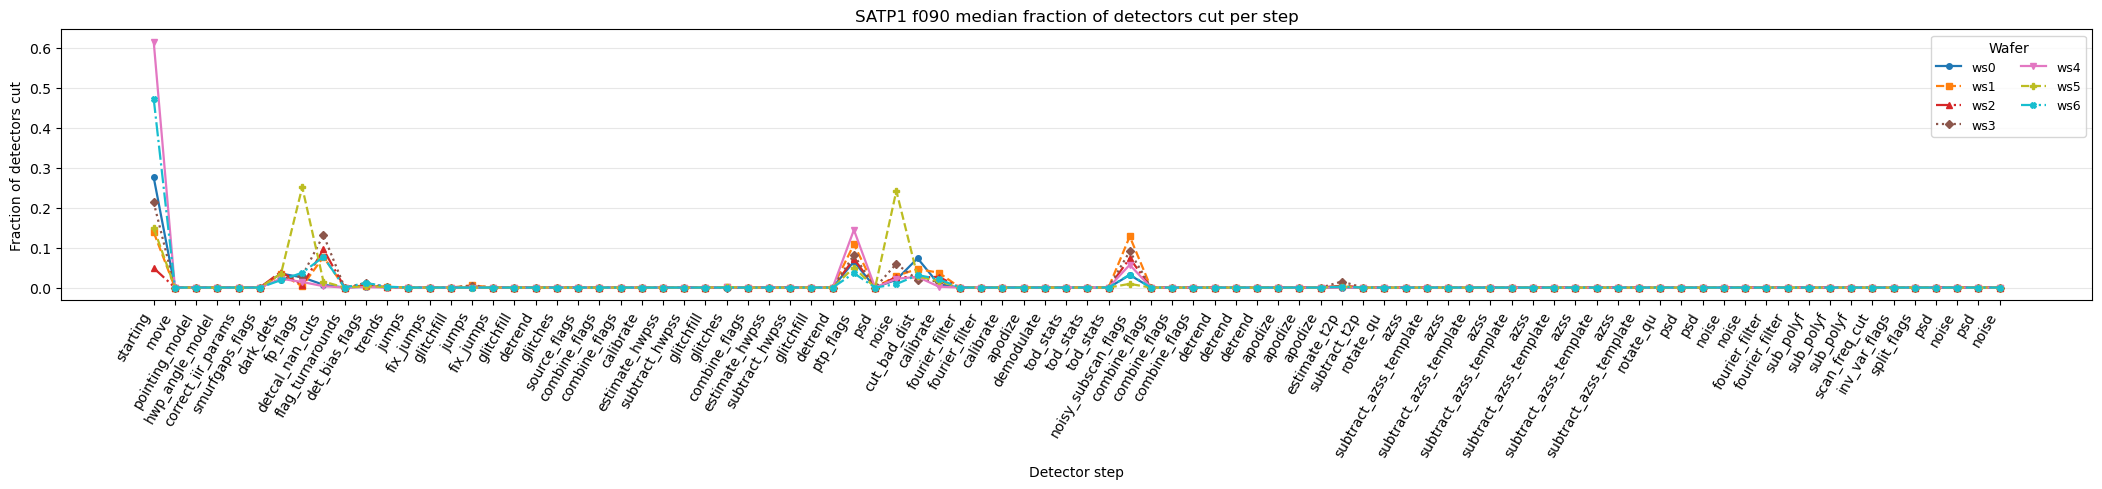

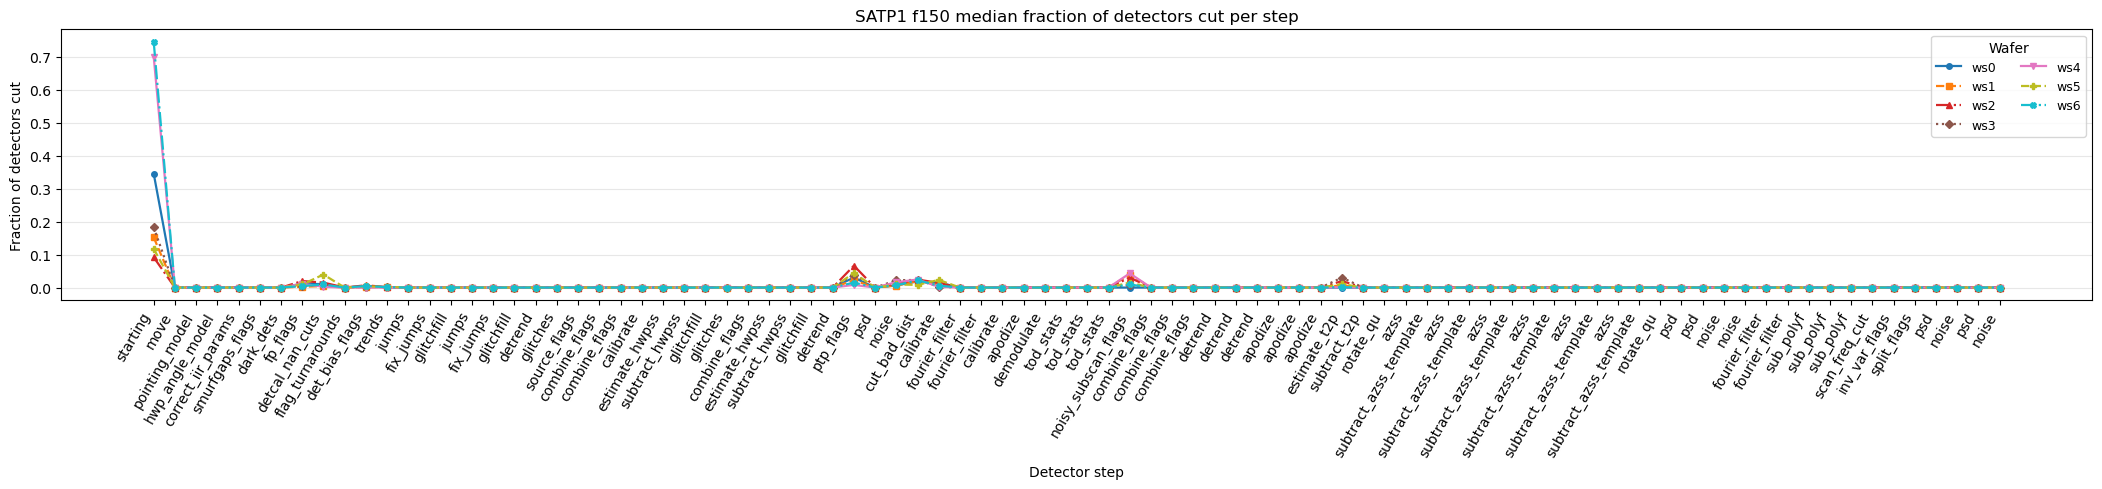

Rendered median detectors-cut curves for 2 bands.


In [17]:
# Per-band detector-step median cuts curves with all wafers overlaid.

cuts_plot_rows = [row for row in bundle['obs_rows'] if row.get('success') == 1]
step_info = bundle['detector_steps']
step_labels = [step['step_name'] for step in step_info]
step_columns = [step['column'] for step in step_info]

output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

wafer_band_keys = sorted({
    (row.get('wafer'), row.get('band'))
    for row in cuts_plot_rows
    if row.get('wafer') is not None and row.get('band') is not None
})

bands_in_data = sorted({band for _, band in wafer_band_keys})
wafer_names = sorted({wafer for wafer, _ in wafer_band_keys})
line_styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
color_map = plt.cm.get_cmap('tab10', max(len(wafer_names), 1))
wafer_styles = {
    wafer: {
        'color': color_map(index % 10),
        'linestyle': line_styles[index % len(line_styles)],
        'marker': markers[index % len(markers)],
    }
    for index, wafer in enumerate(wafer_names)
}

rendered_bands = 0
for band in bands_in_data:
    fig_w = max(12, 0.24 * len(step_labels))
    fig, ax = plt.subplots(figsize=(fig_w, 5))
    plotted_any = False

    for wafer in wafer_names:
        wafer_rows = [
            row for row in cuts_plot_rows
            if row.get('wafer') == wafer and row.get('band') == band
        ]
        if not wafer_rows:
            continue

        cut_medians = []
        valid_positions = []
        for idx, (step_label, step_col) in enumerate(zip(step_labels, step_columns)):
            if idx == 0:
                cuts = [
                    DETECTORS_PER_WAFER_PER_BAND - float(row[step_col])
                    for row in wafer_rows
                    if row.get(step_col) is not None and not np.isnan(float(row[step_col]))
                ]
            else:
                prev_col = step_columns[idx - 1]
                cuts = [
                    float(row[prev_col]) - float(row[step_col])
                    for row in wafer_rows
                    if row.get(prev_col) is not None and row.get(step_col) is not None
                    and not np.isnan(float(row[prev_col])) and not np.isnan(float(row[step_col]))
                ]
            if cuts:
                cut_medians.append(float(np.median(cuts)) / DETECTORS_PER_WAFER_PER_BAND)
                valid_positions.append(idx + 1)

        if not cut_medians:
            continue

        style = wafer_styles[wafer]
        ax.plot(
            valid_positions,
            cut_medians,
            label=str(wafer),
            color=style['color'],
            linestyle=style['linestyle'],
            marker=style['marker'],
            linewidth=1.6,
            markersize=4,
        )
        plotted_any = True

    if not plotted_any:
        plt.close(fig)
        continue

    ax.set_xticks(range(1, len(step_labels) + 1))
    ax.set_xticklabels(step_labels, rotation=60, ha='right')
    ax.set_ylabel('Fraction of detectors cut')
    ax.set_xlabel('Detector step')
    ax.set_title(f"{config.telescope.upper()} {band} median fraction of detectors cut per step")
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend(title='Wafer', ncol=2, fontsize=9)
    fig.tight_layout()
    fig.savefig(
        output_dir / f'{config.telescope}_{band}_cuts_median_by_wafer.png',
        dpi=150,
        bbox_inches='tight',
    )
    plt.show()
    rendered_bands += 1

print(f'Rendered median detectors-cut curves for {rendered_bands} bands.')


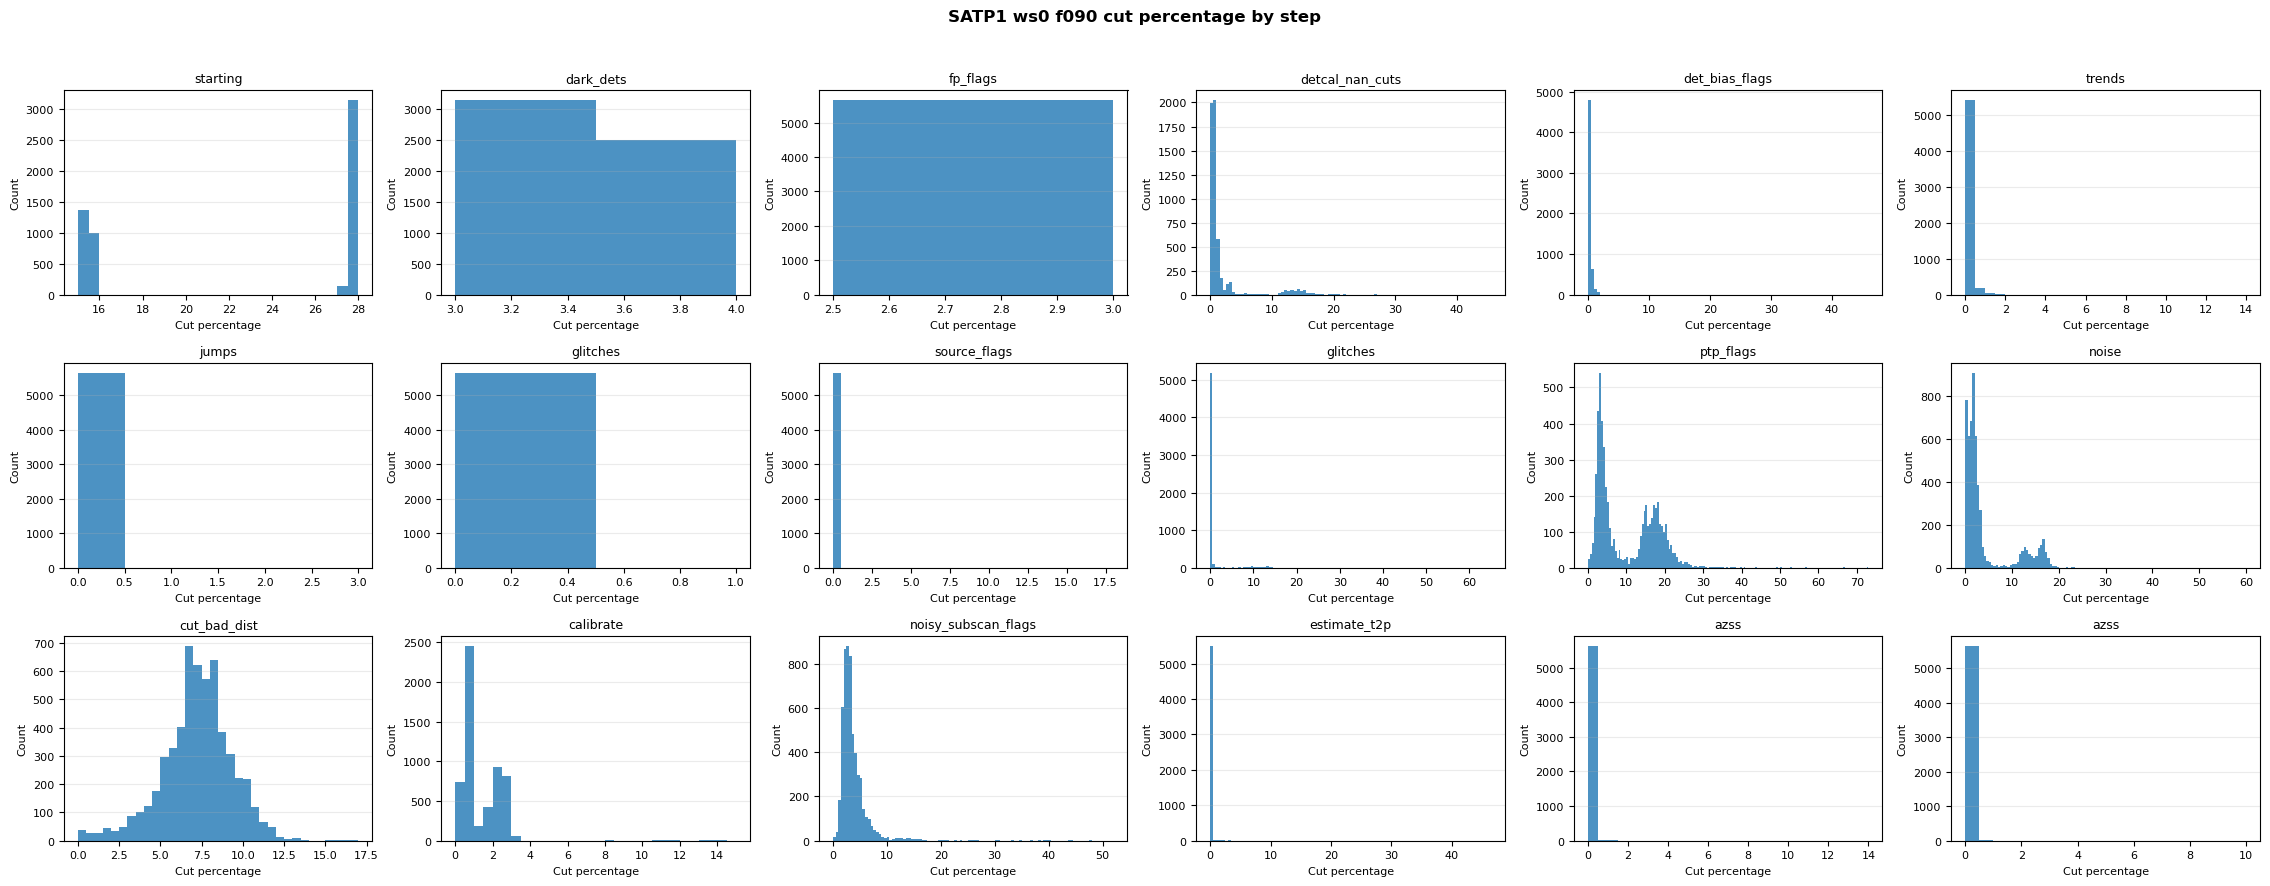

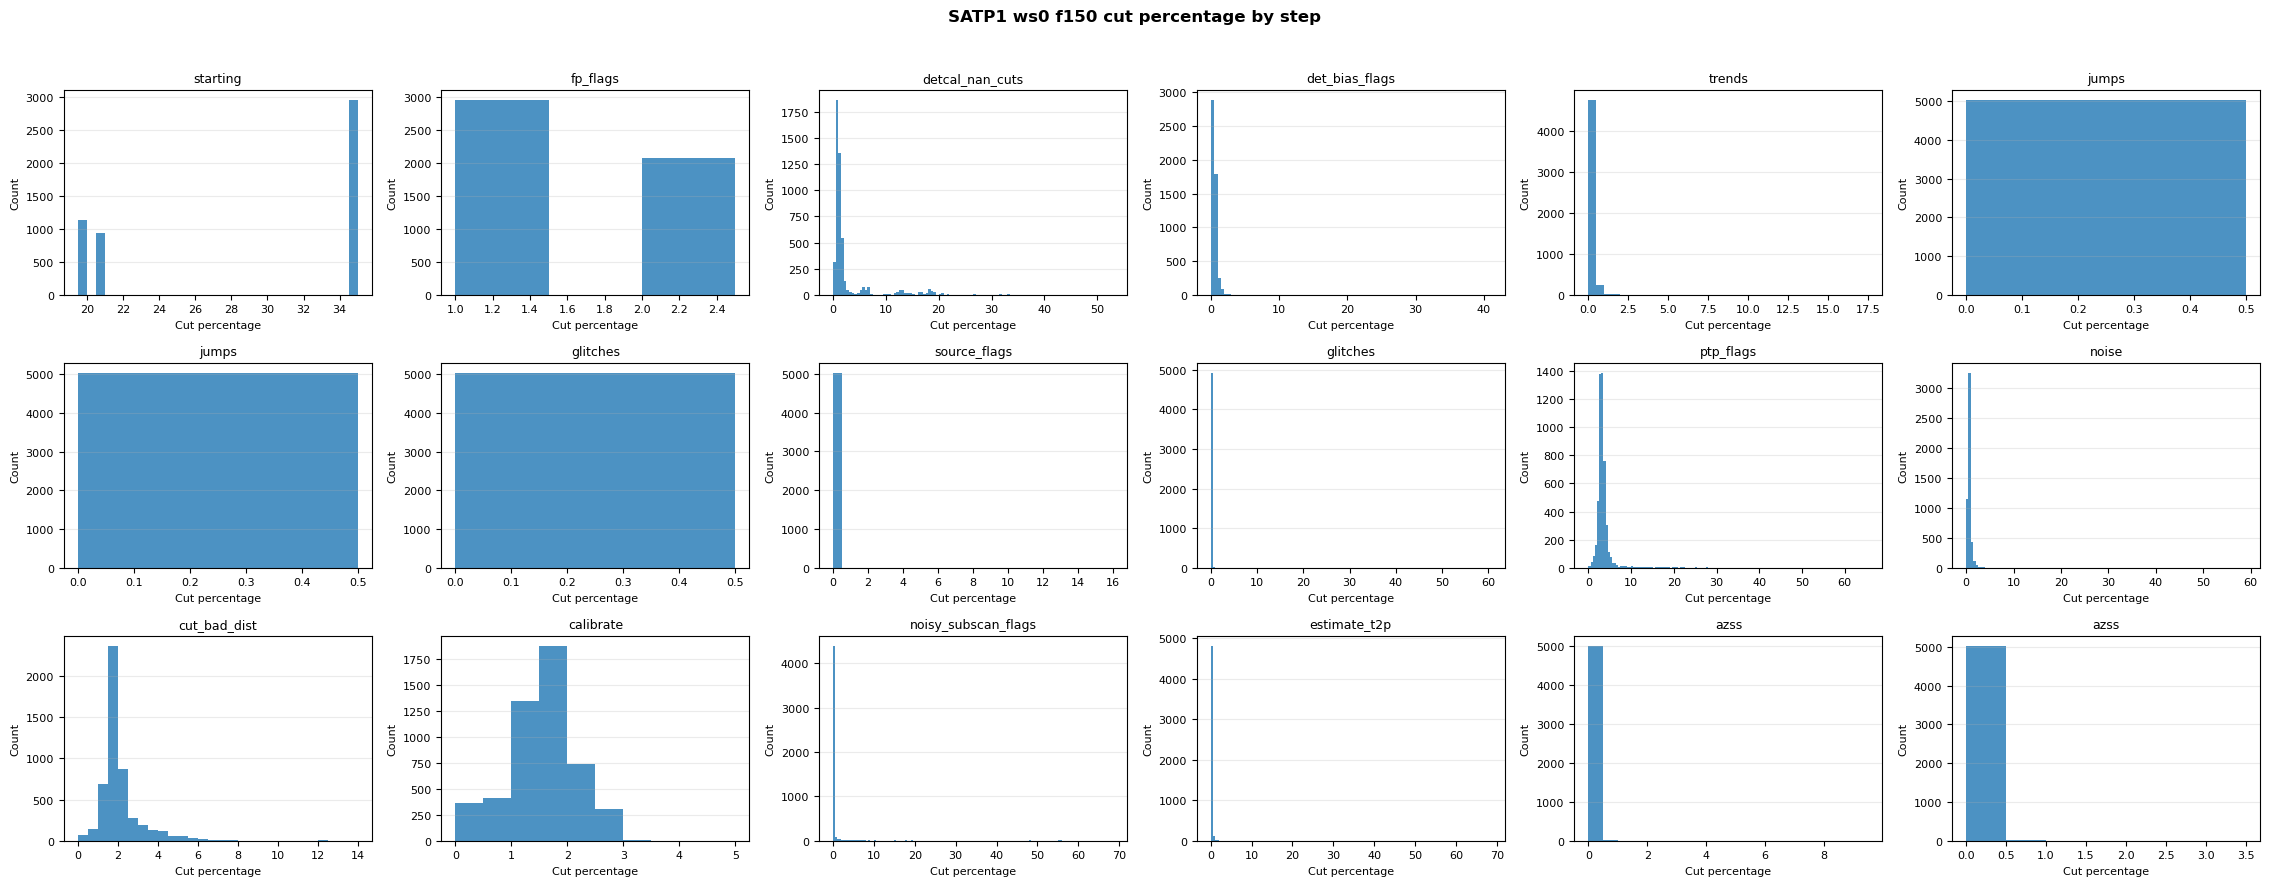

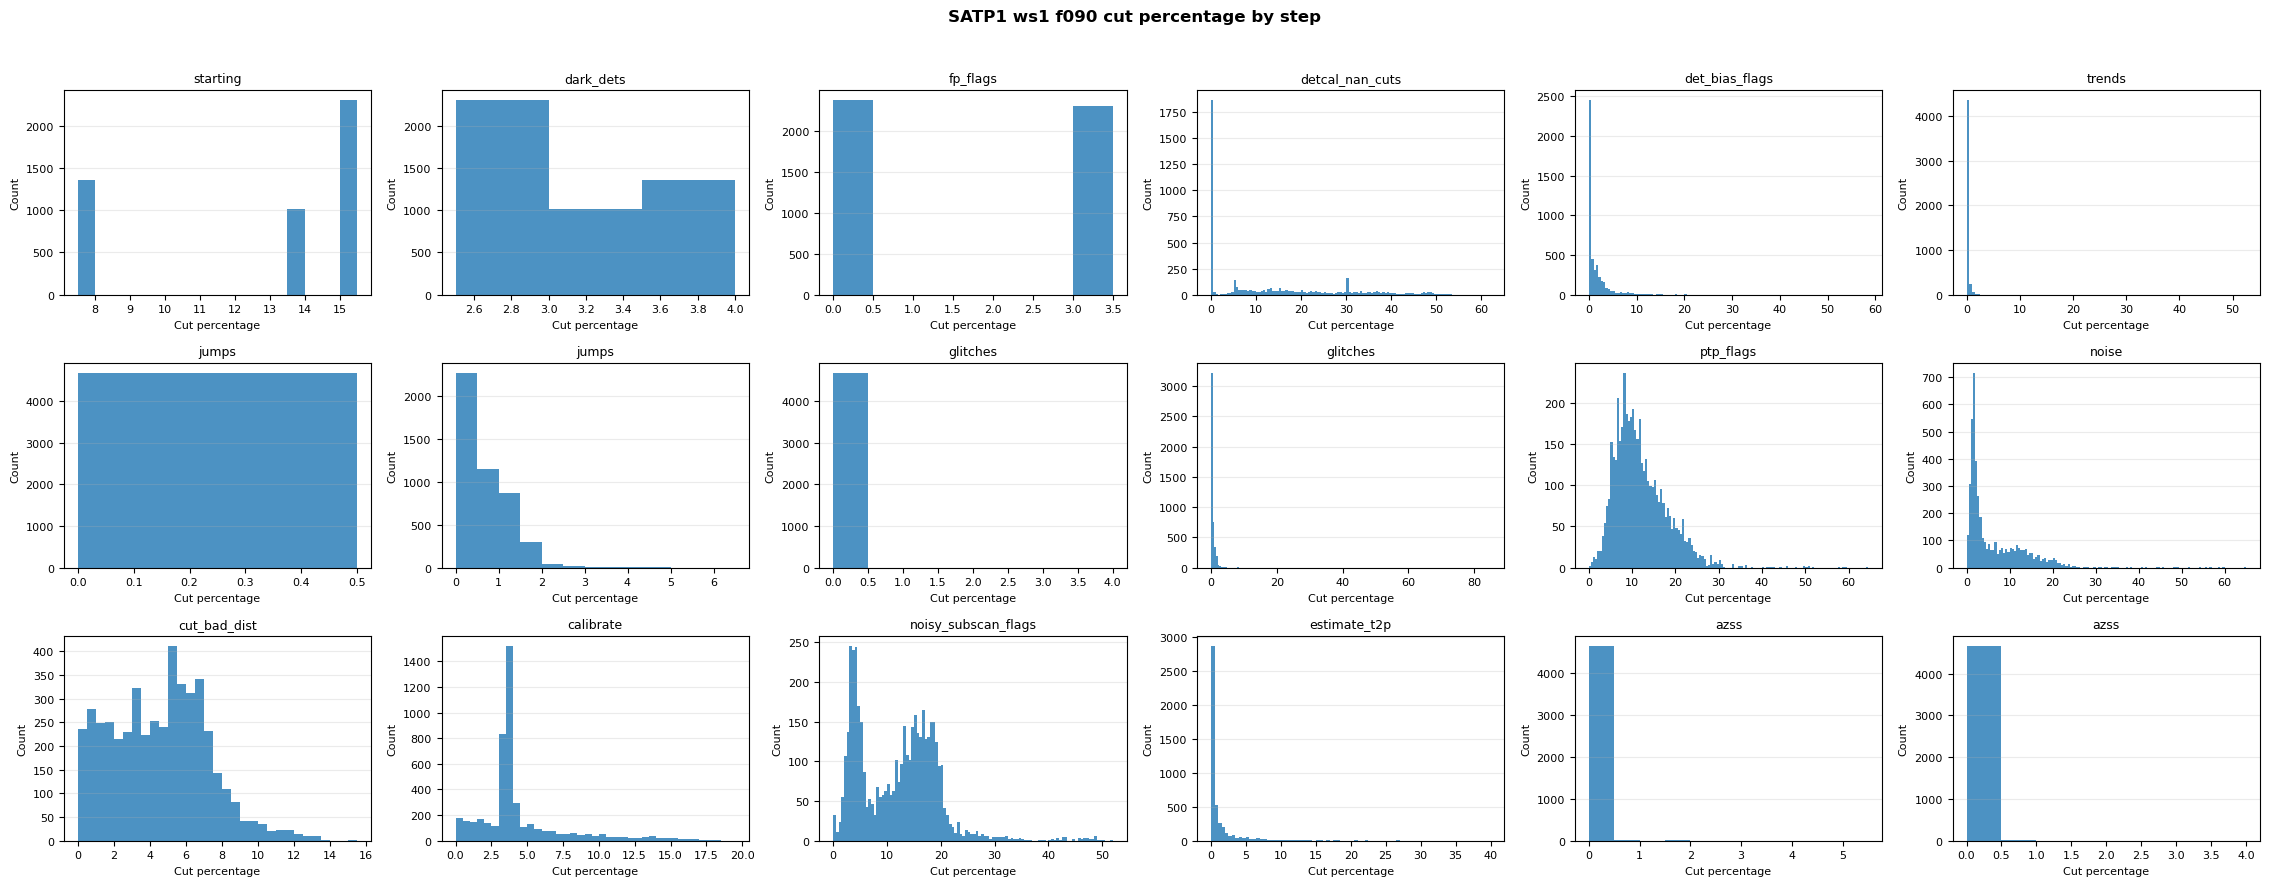

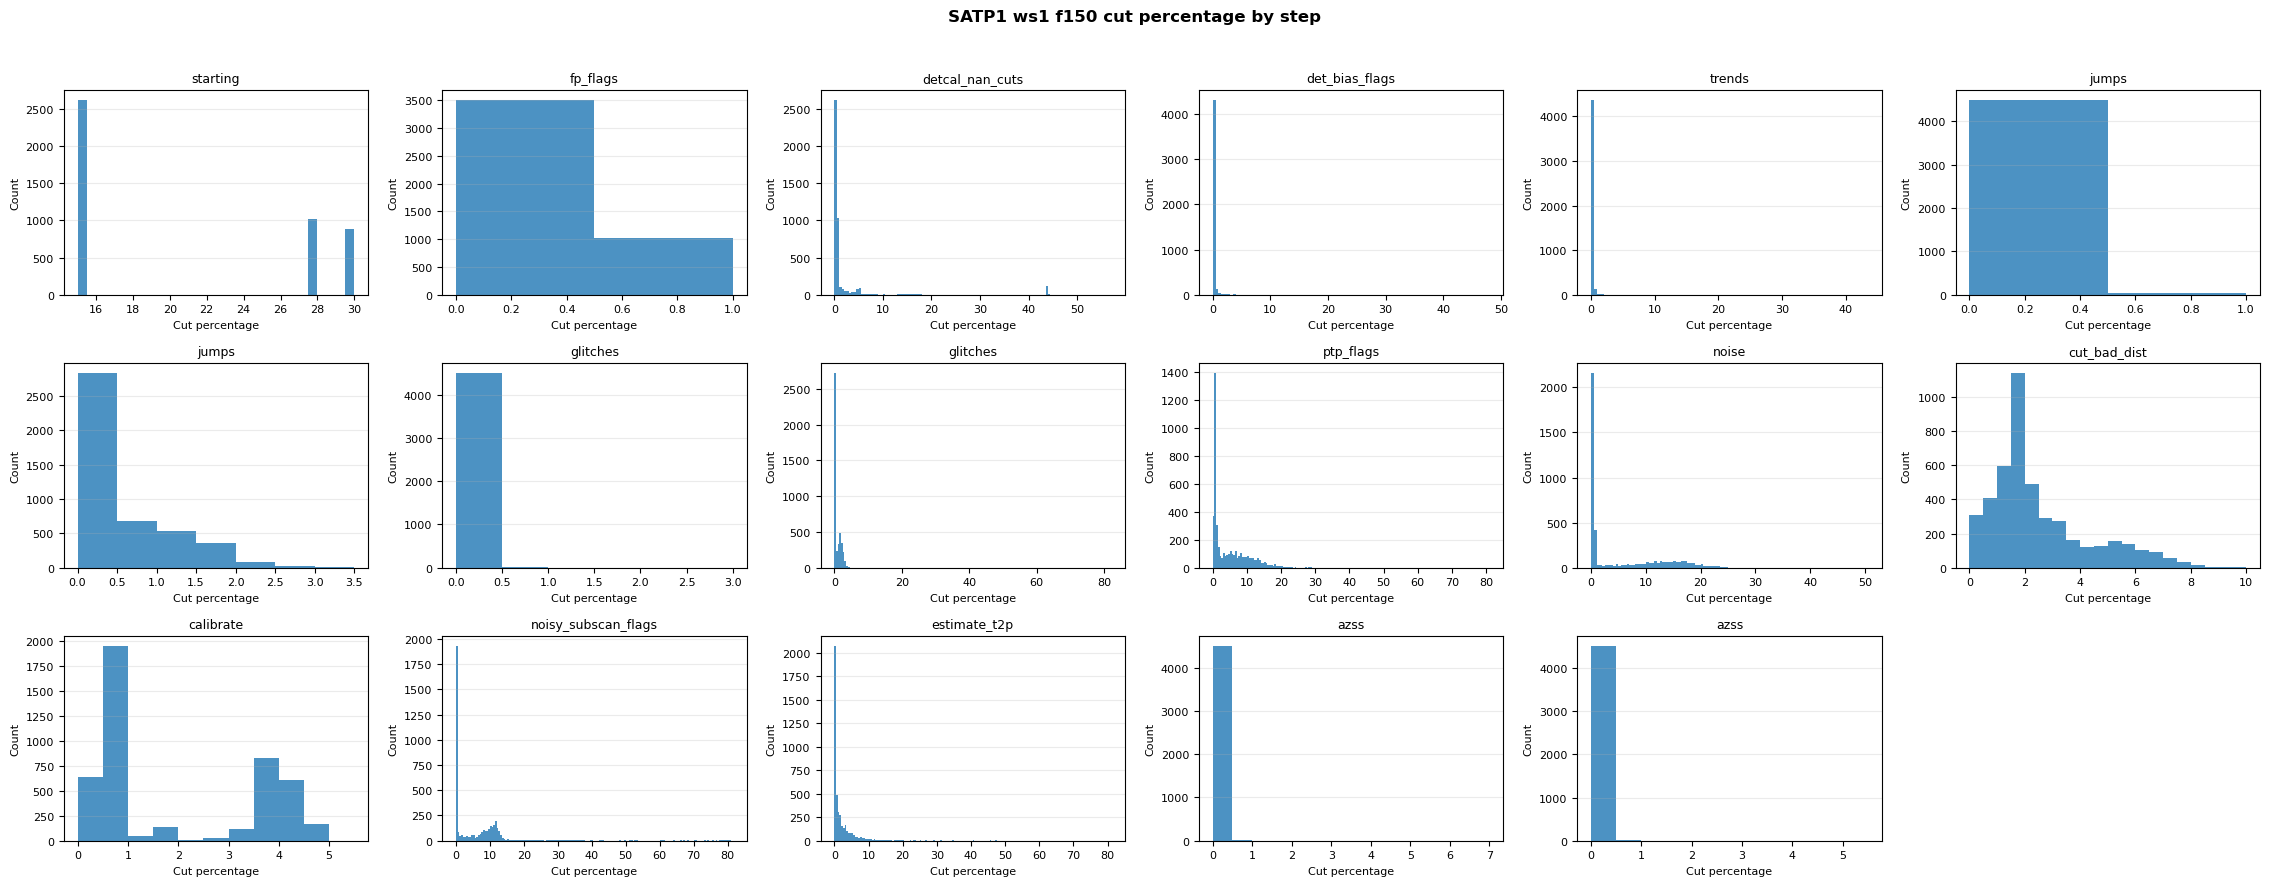

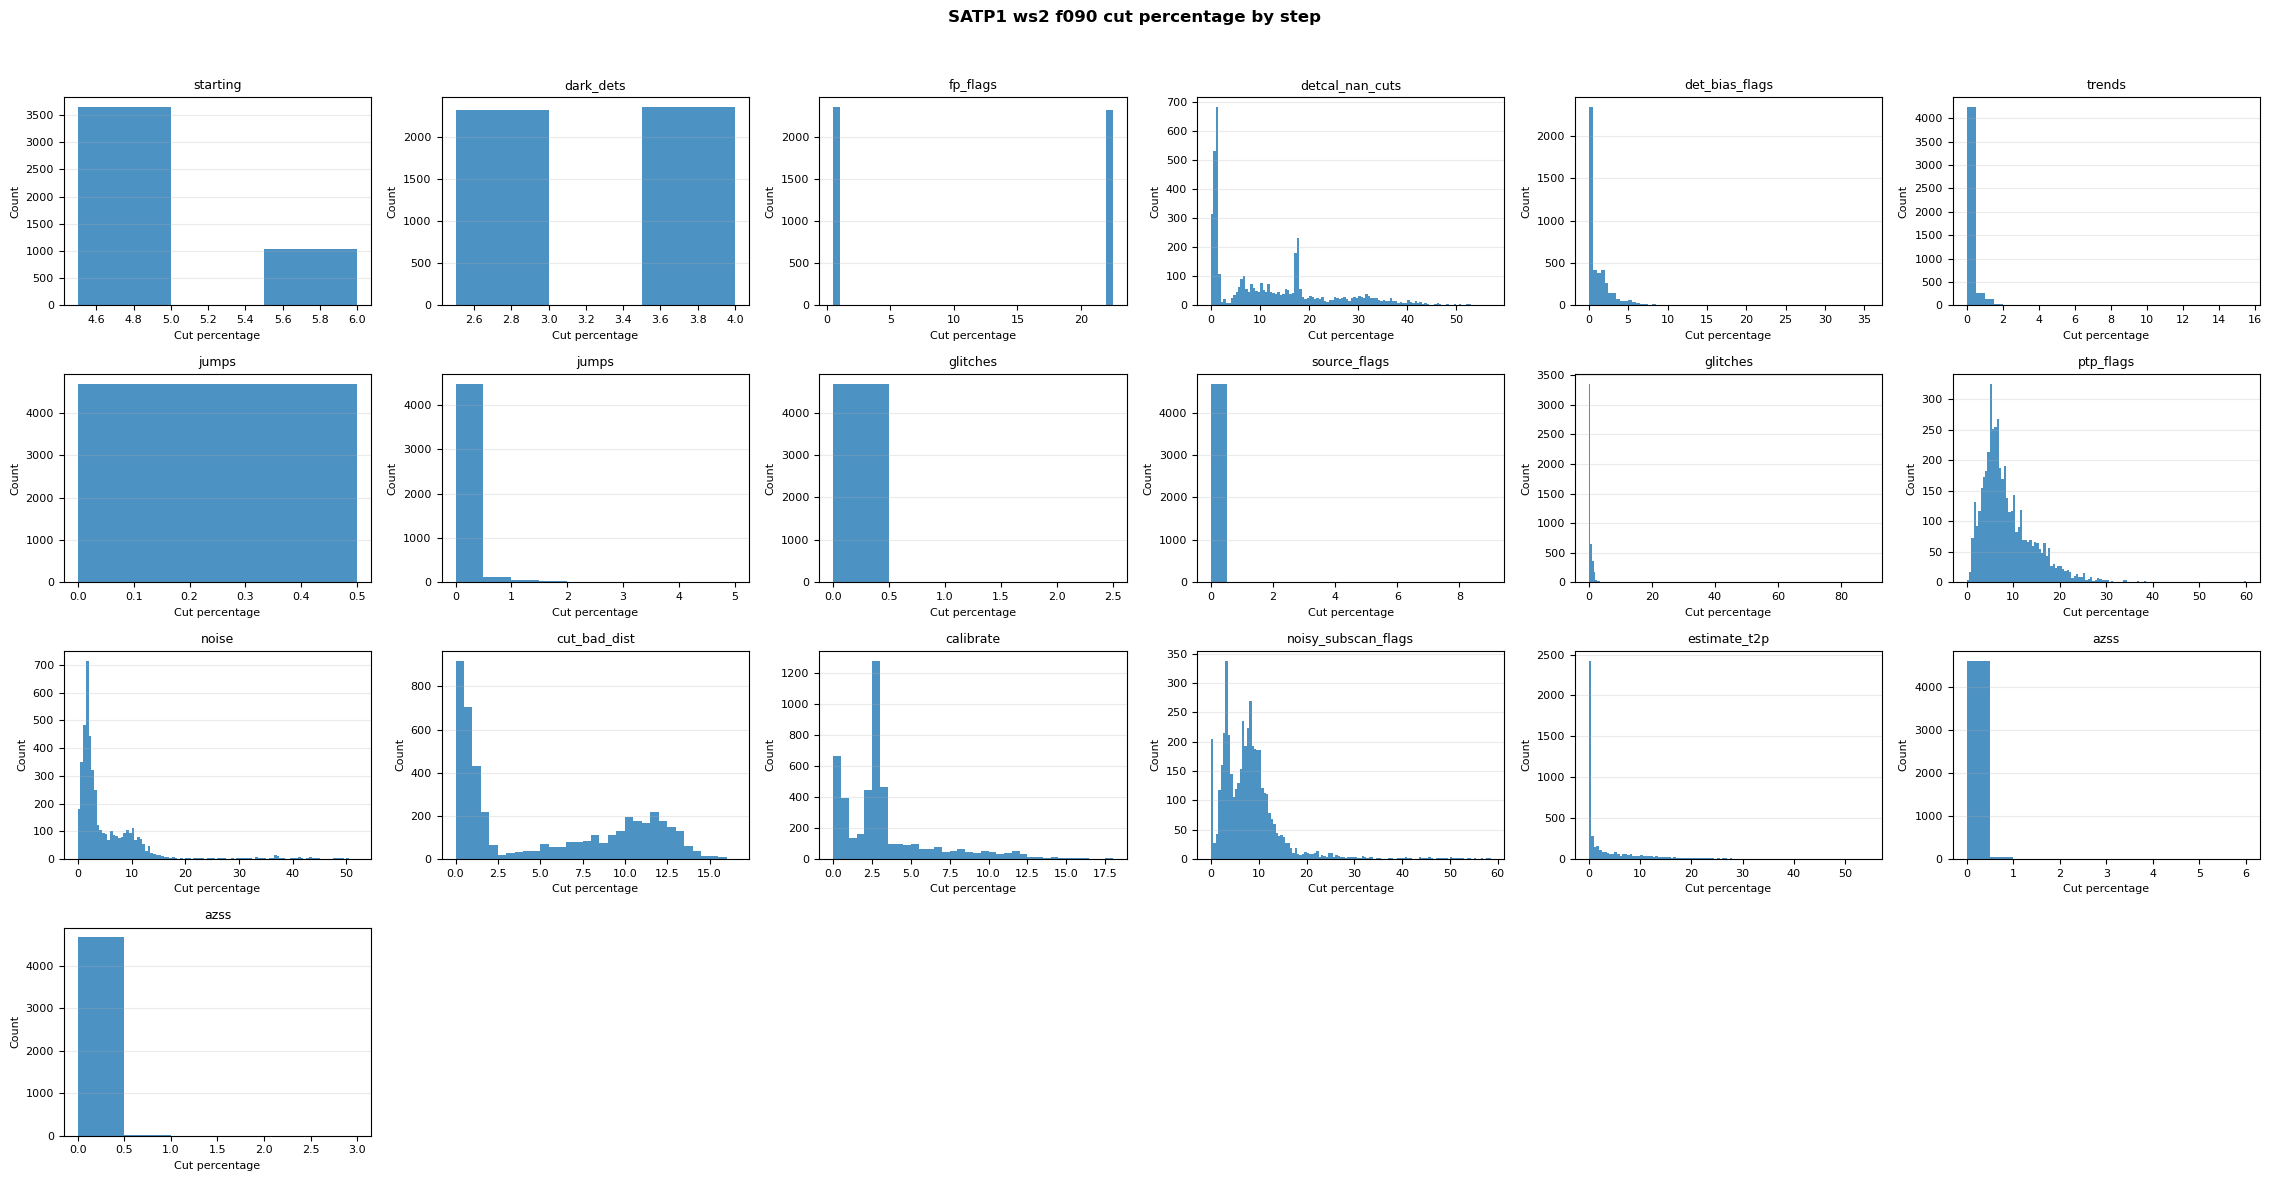

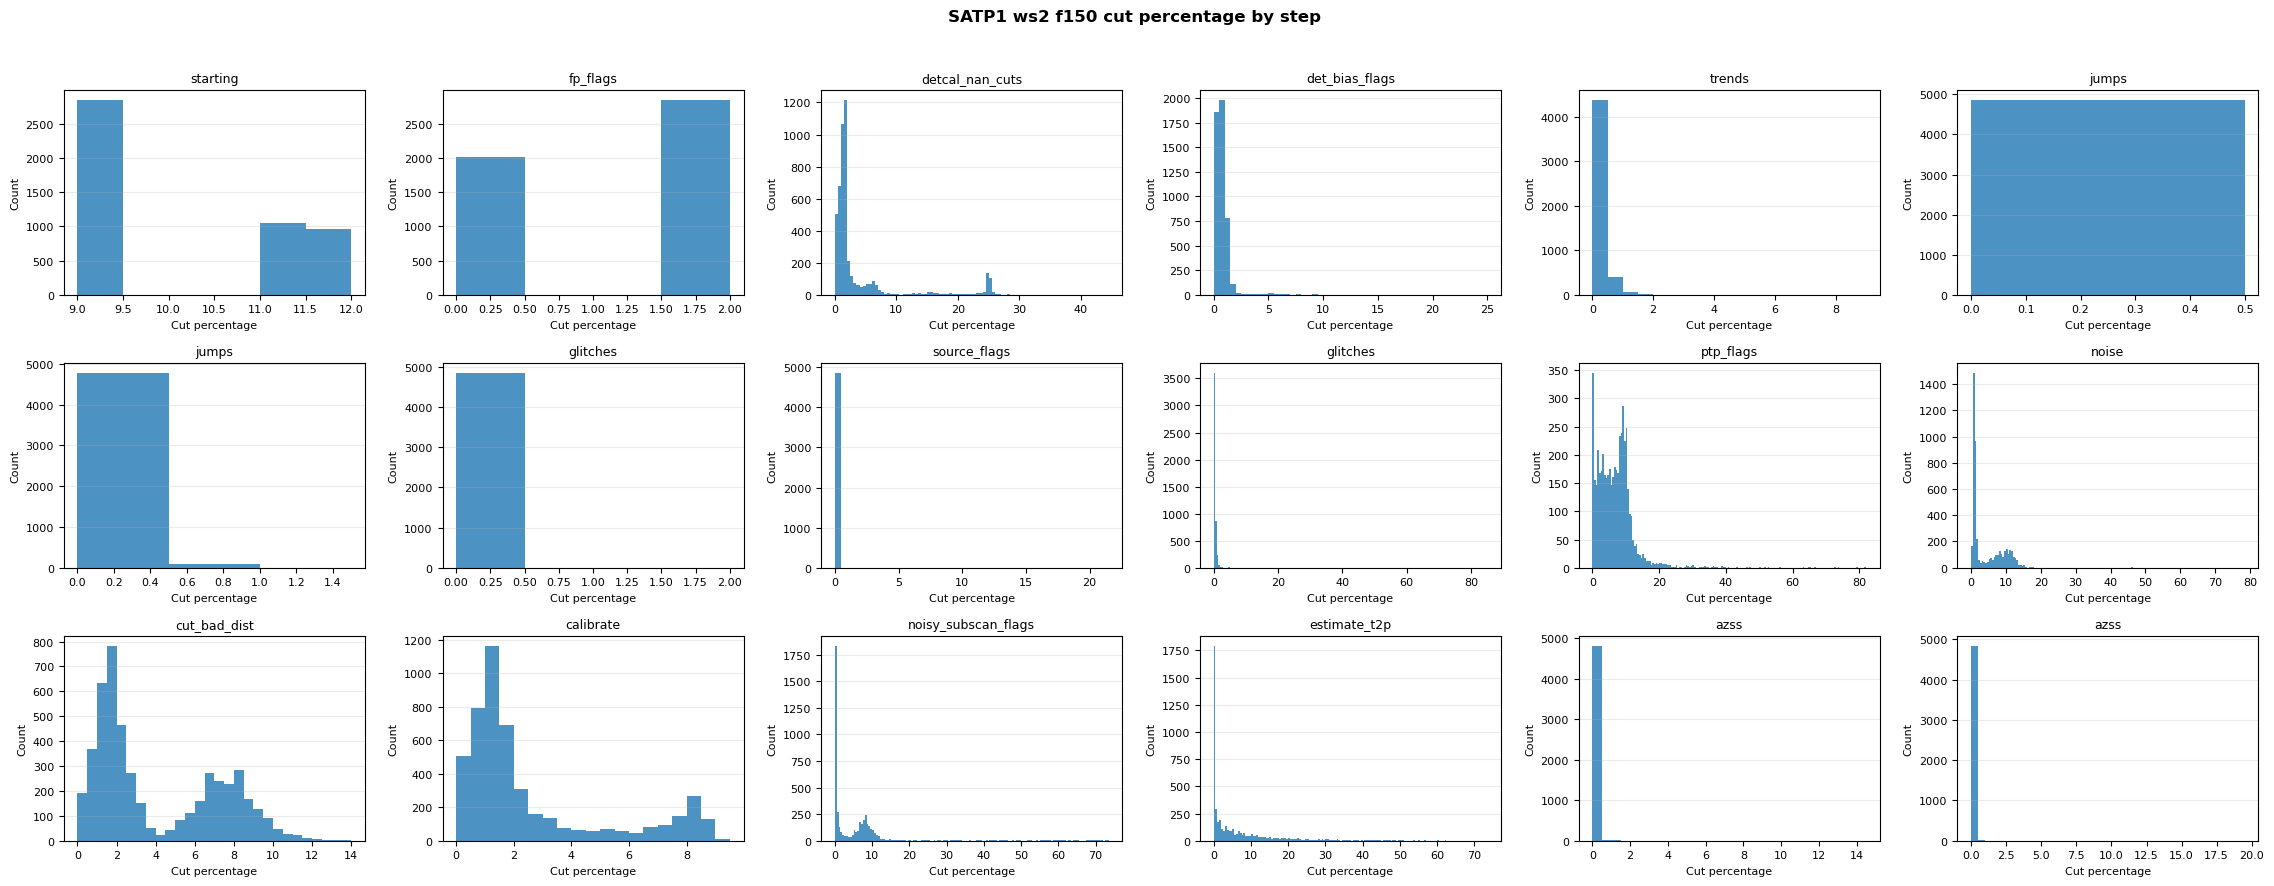

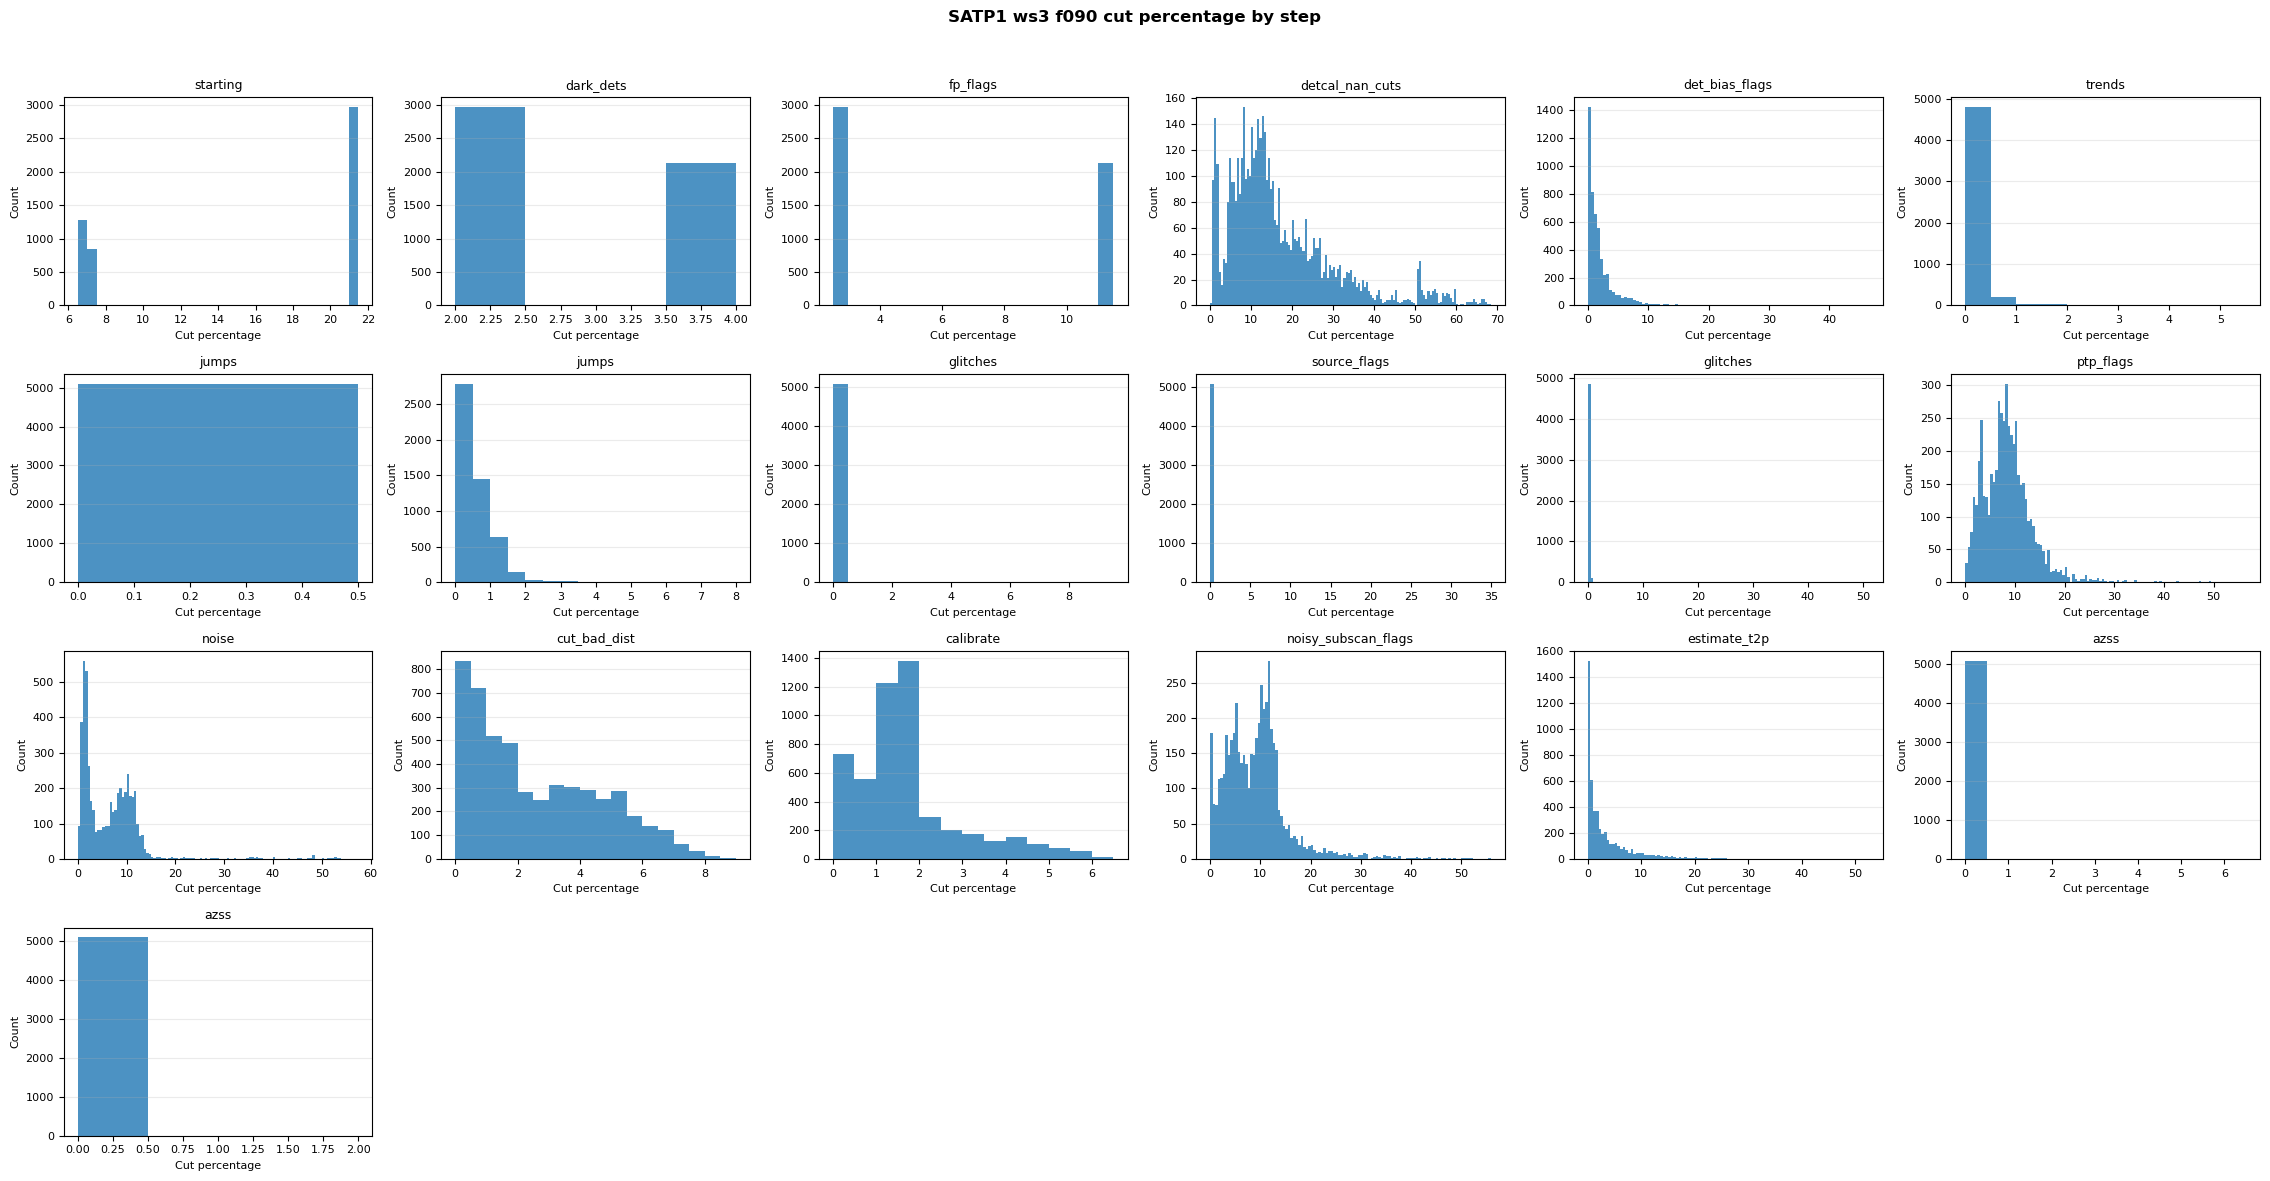

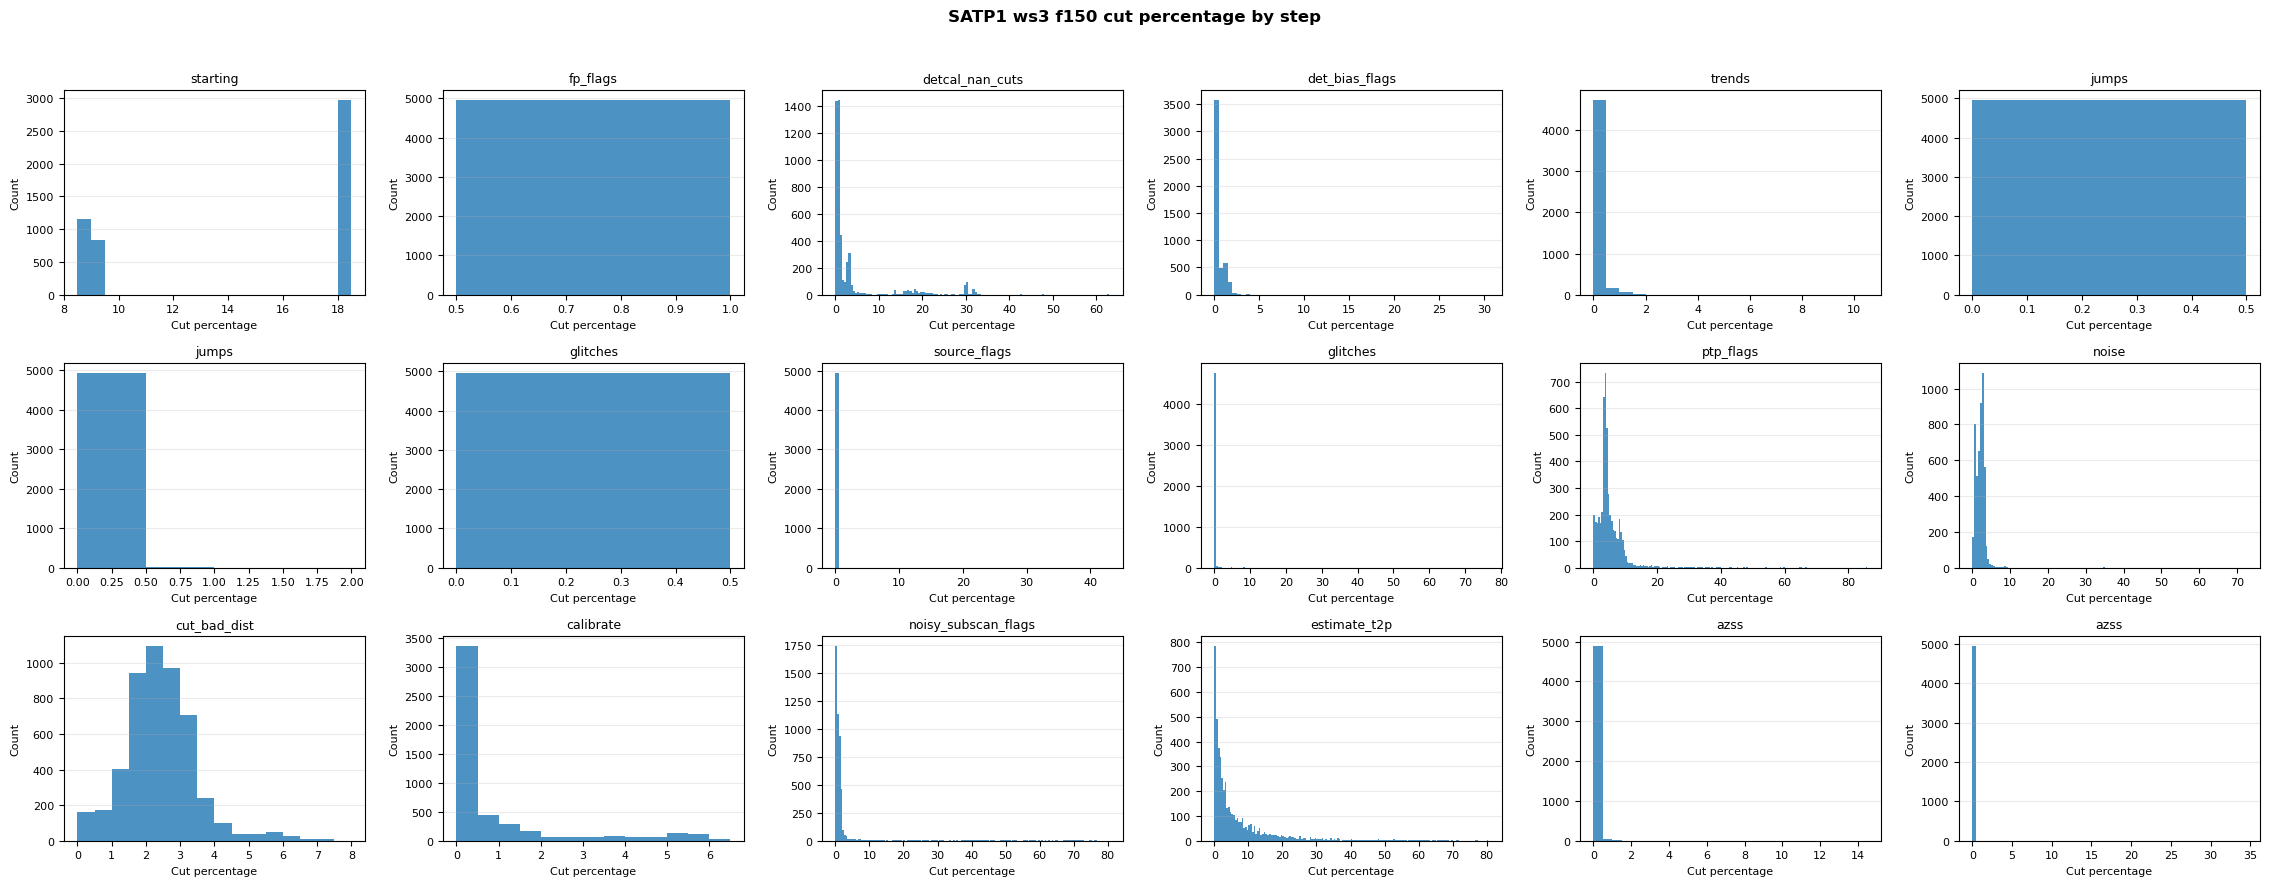

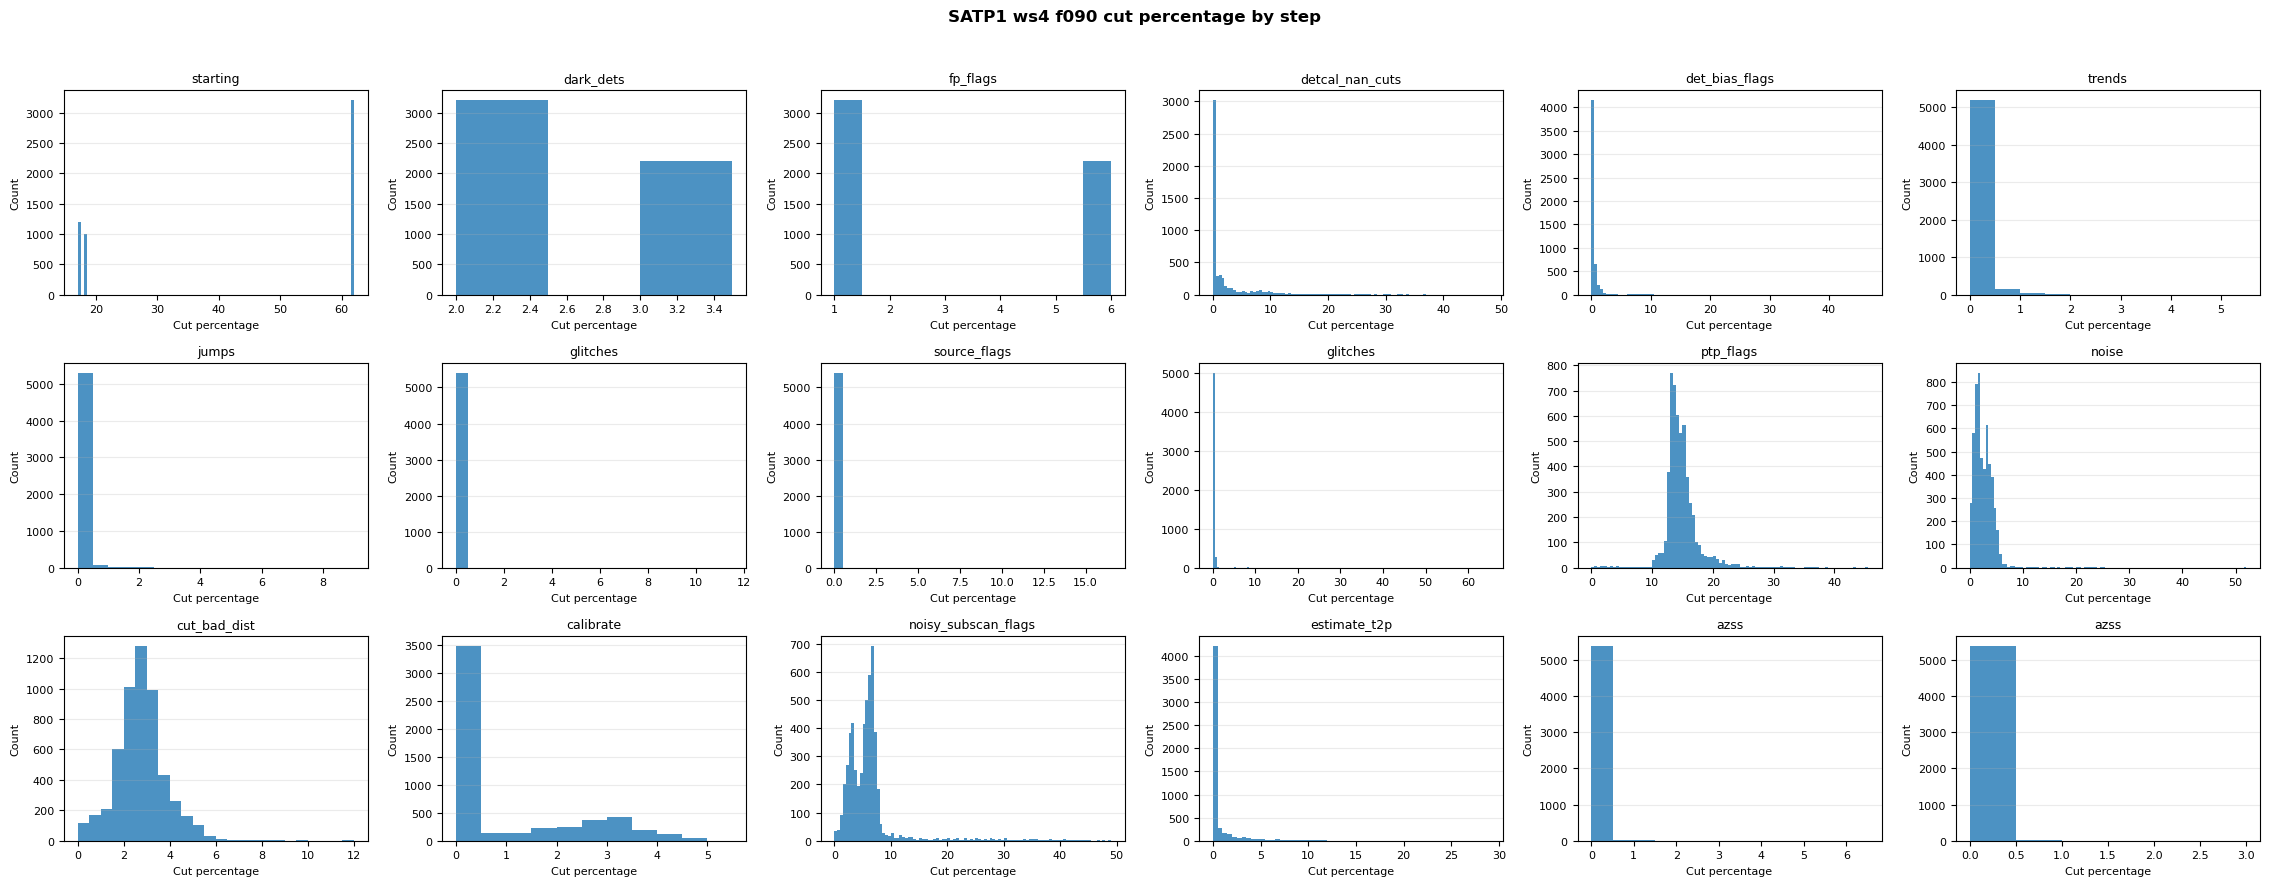

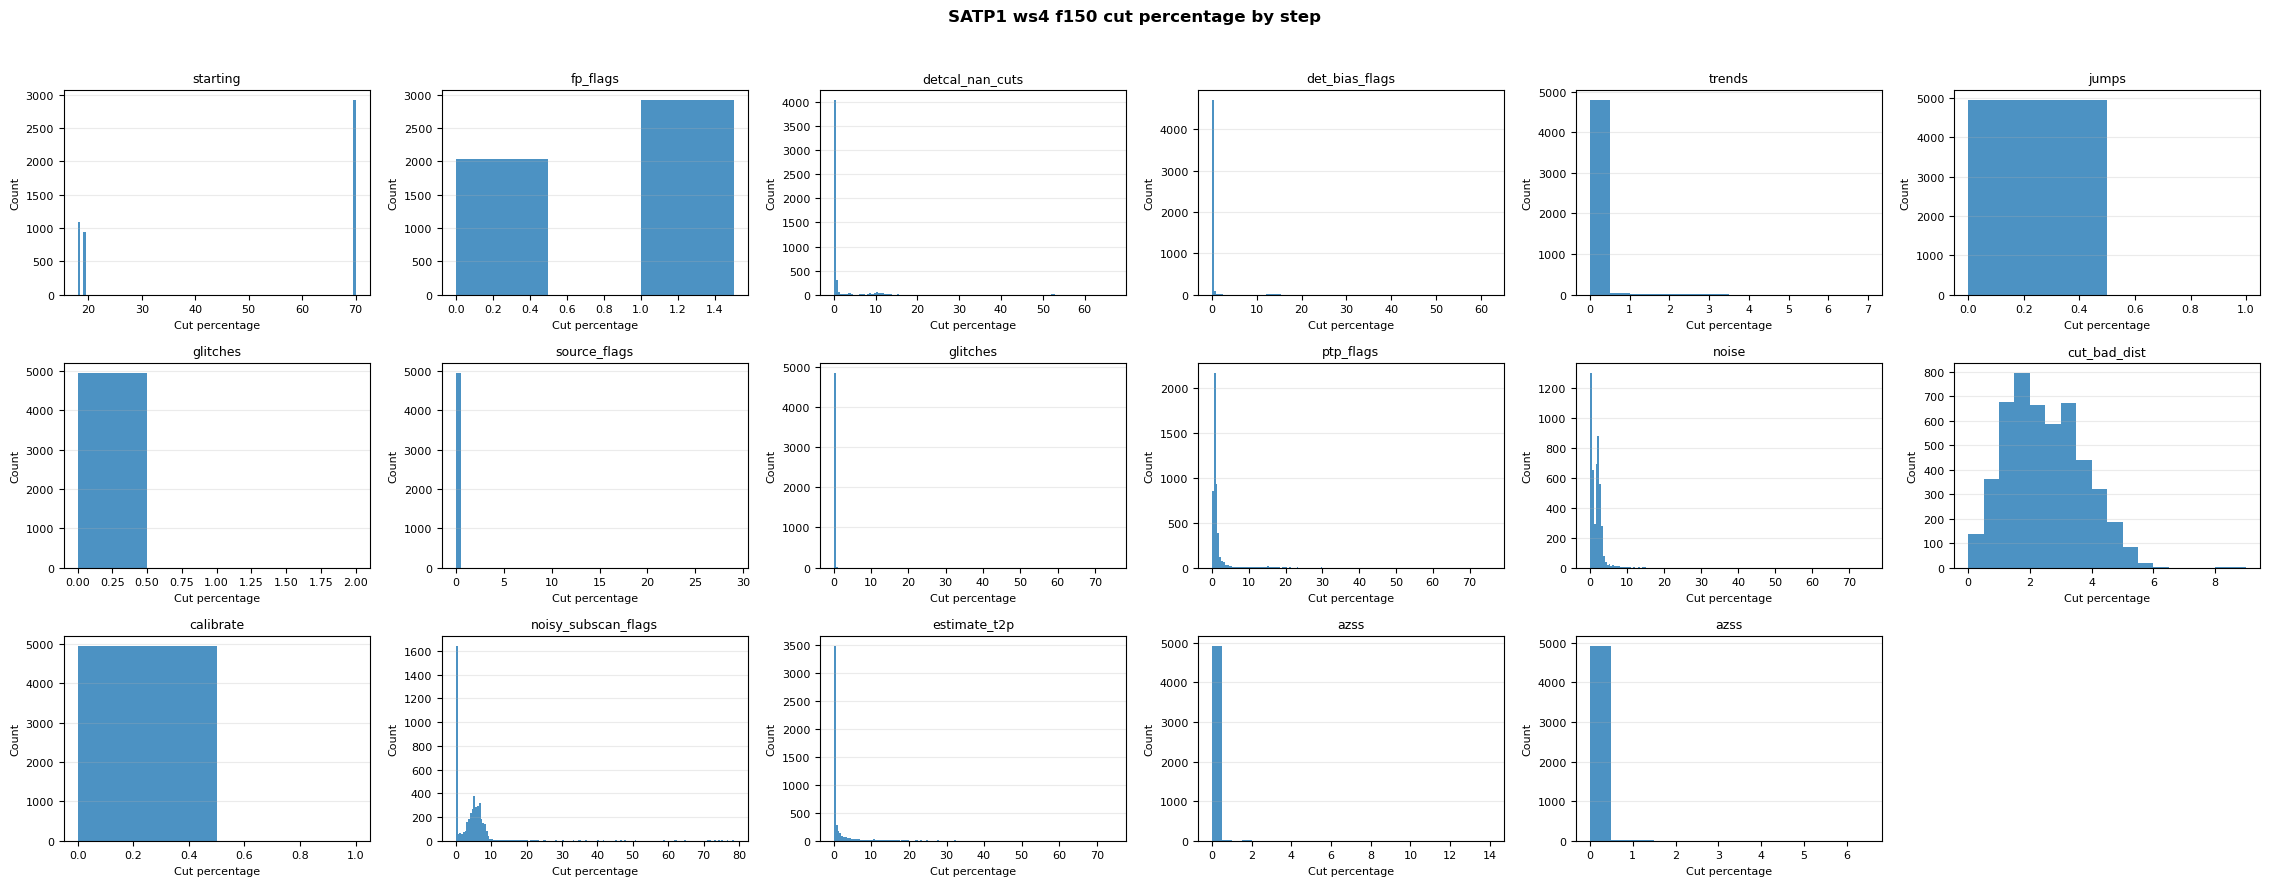

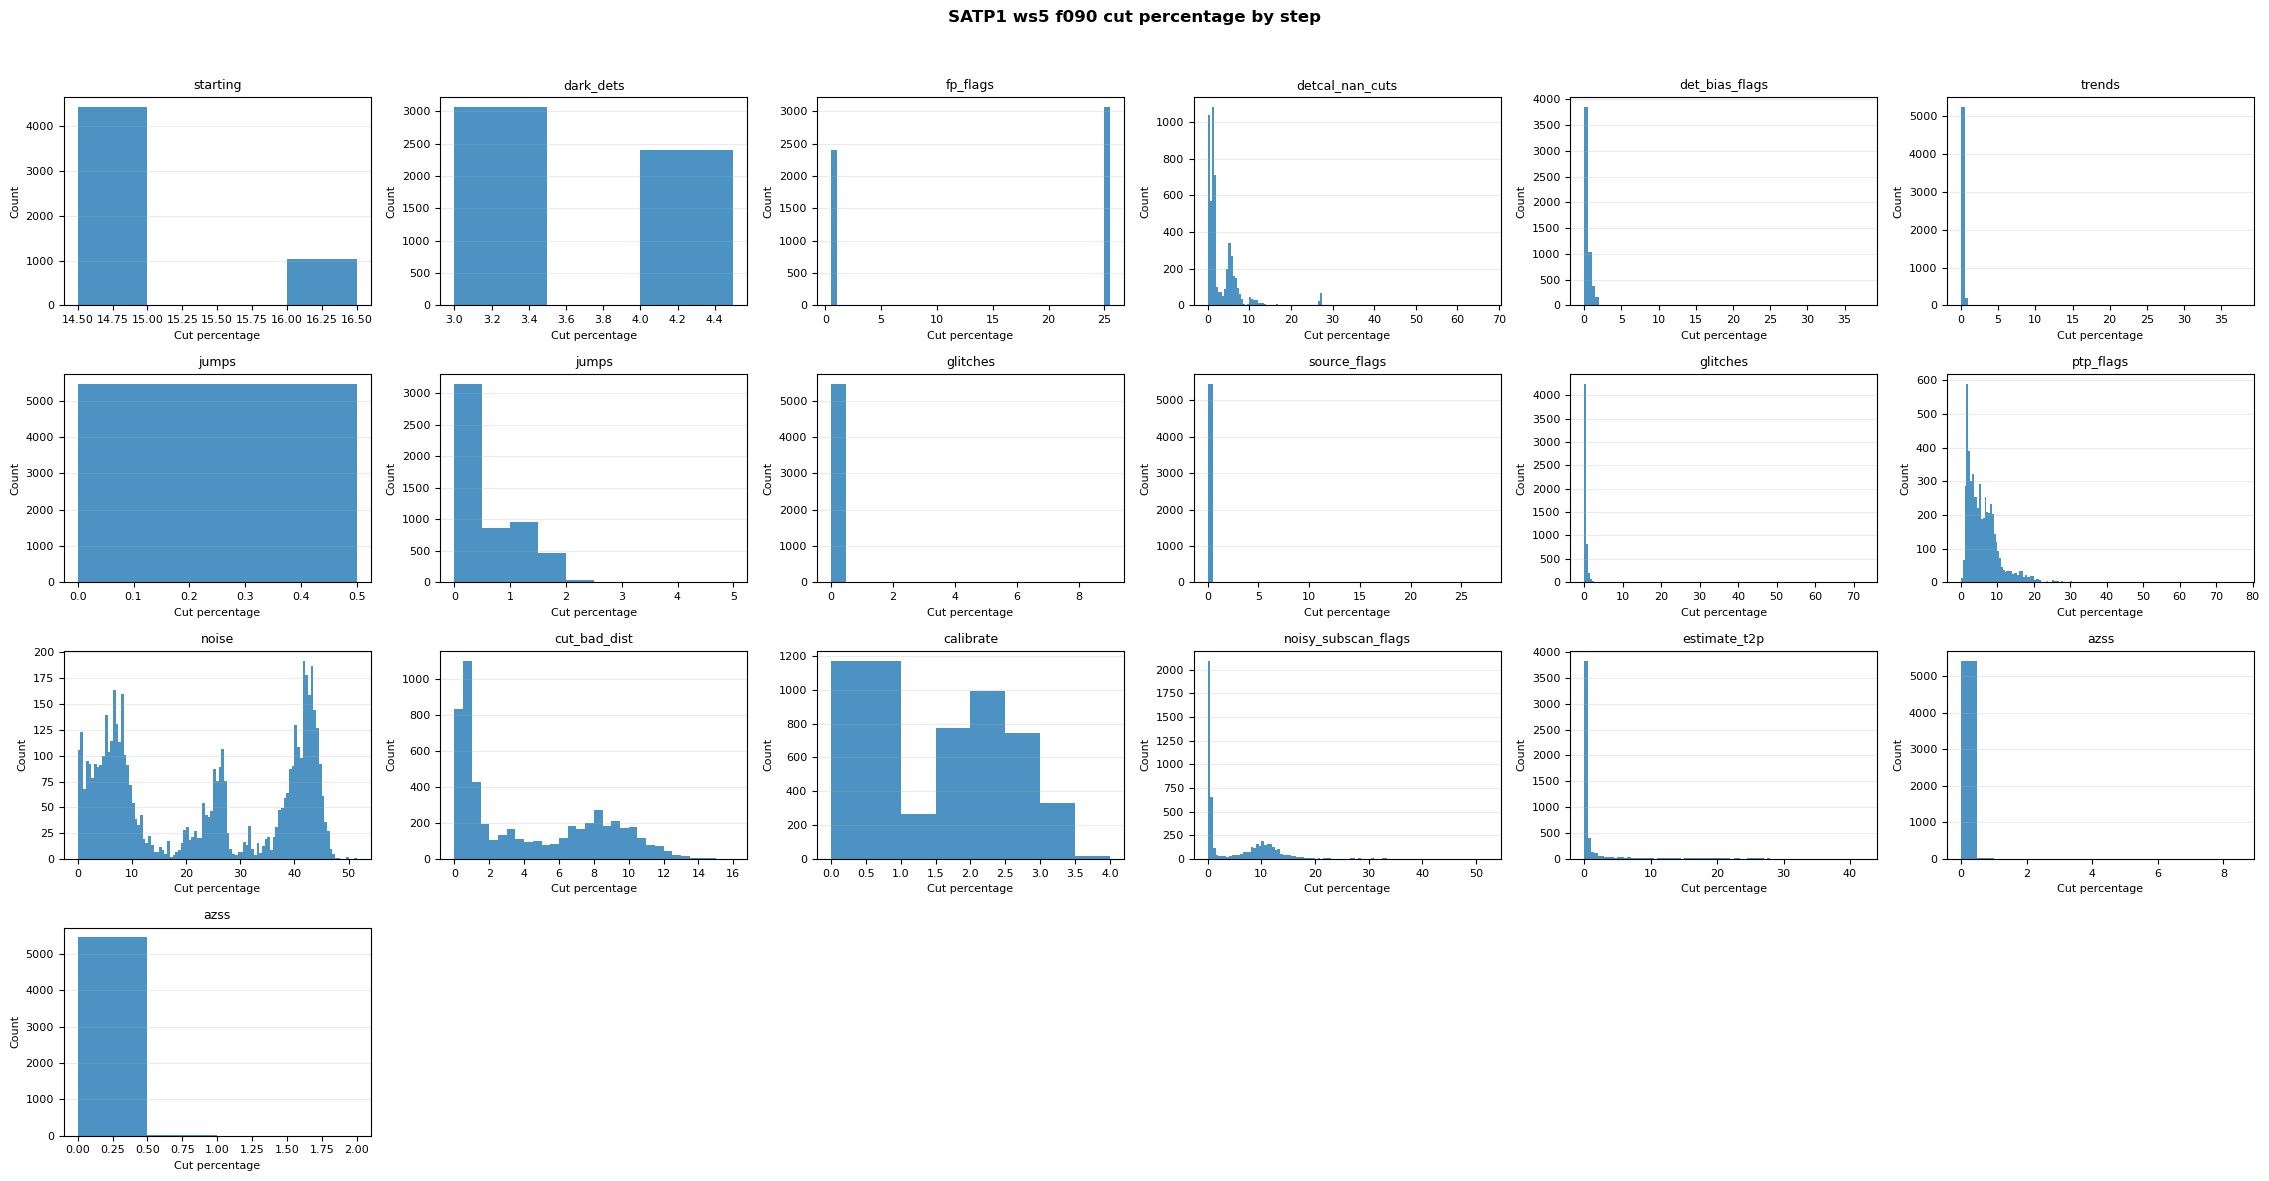

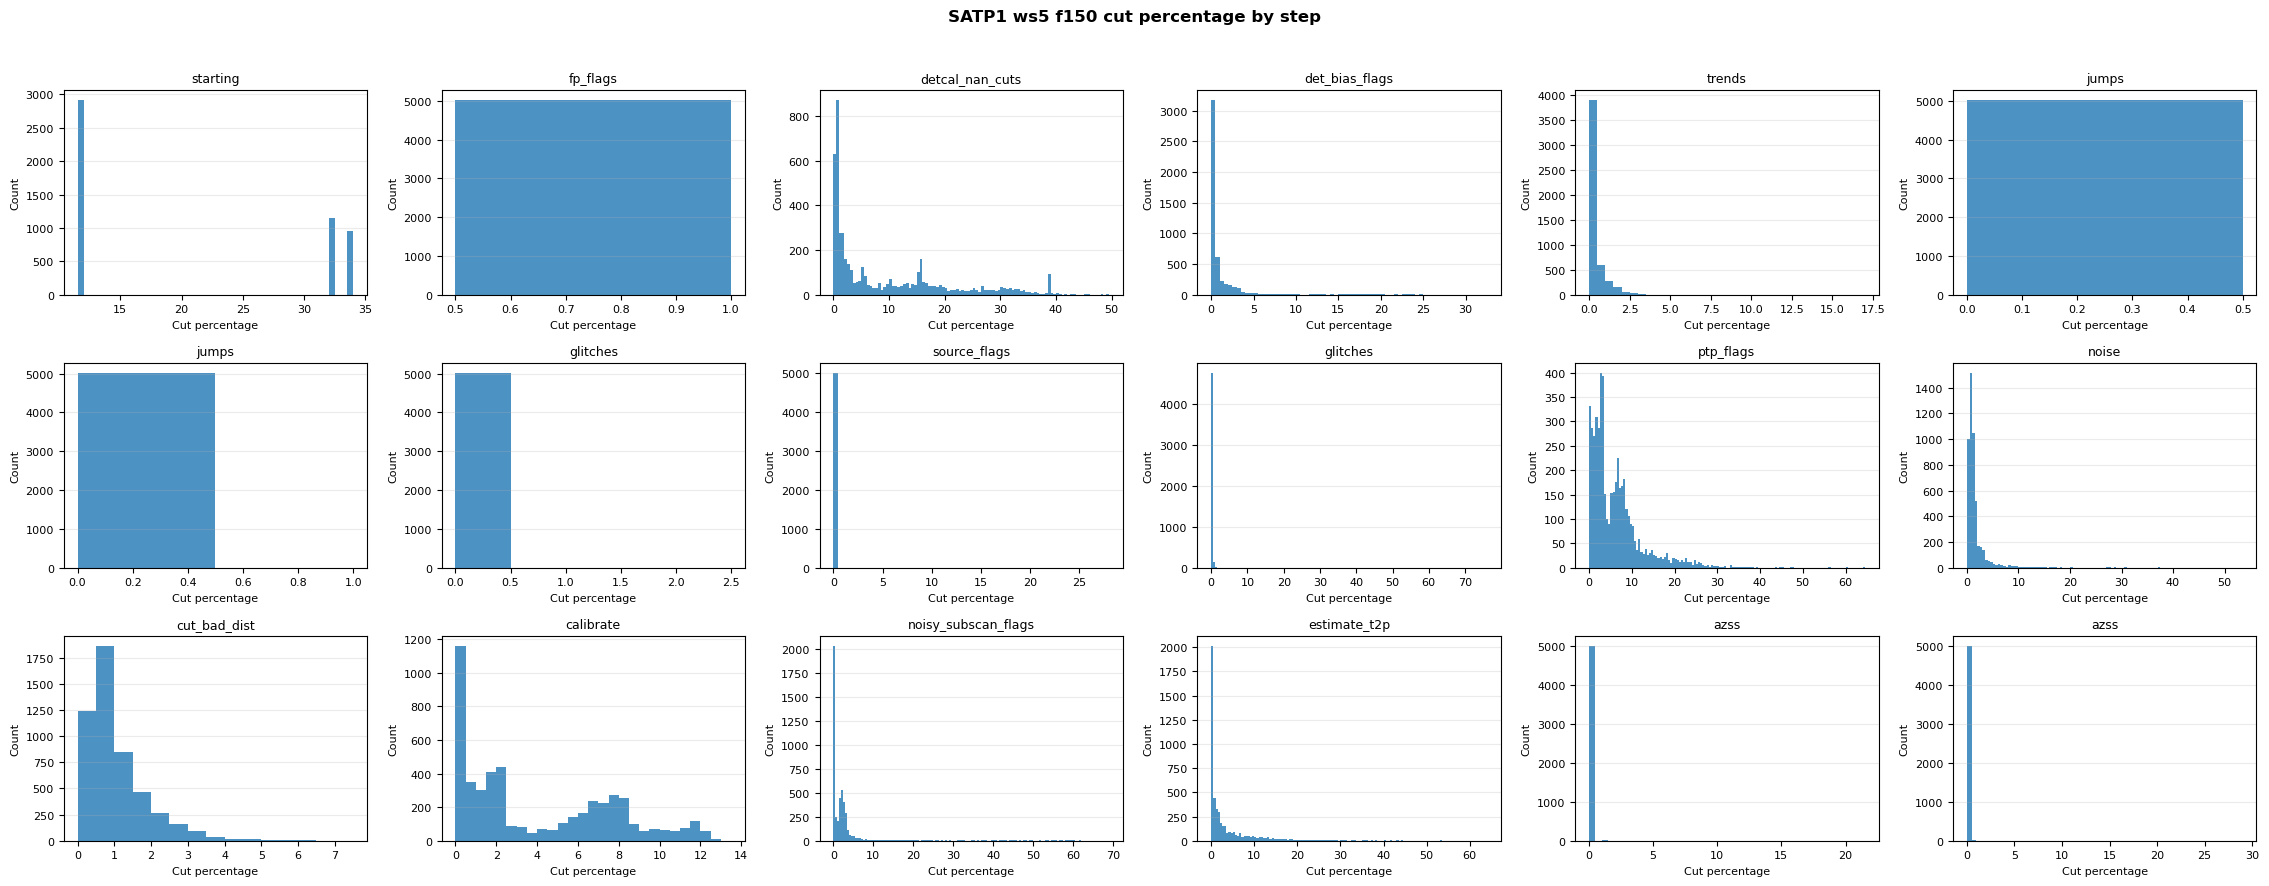

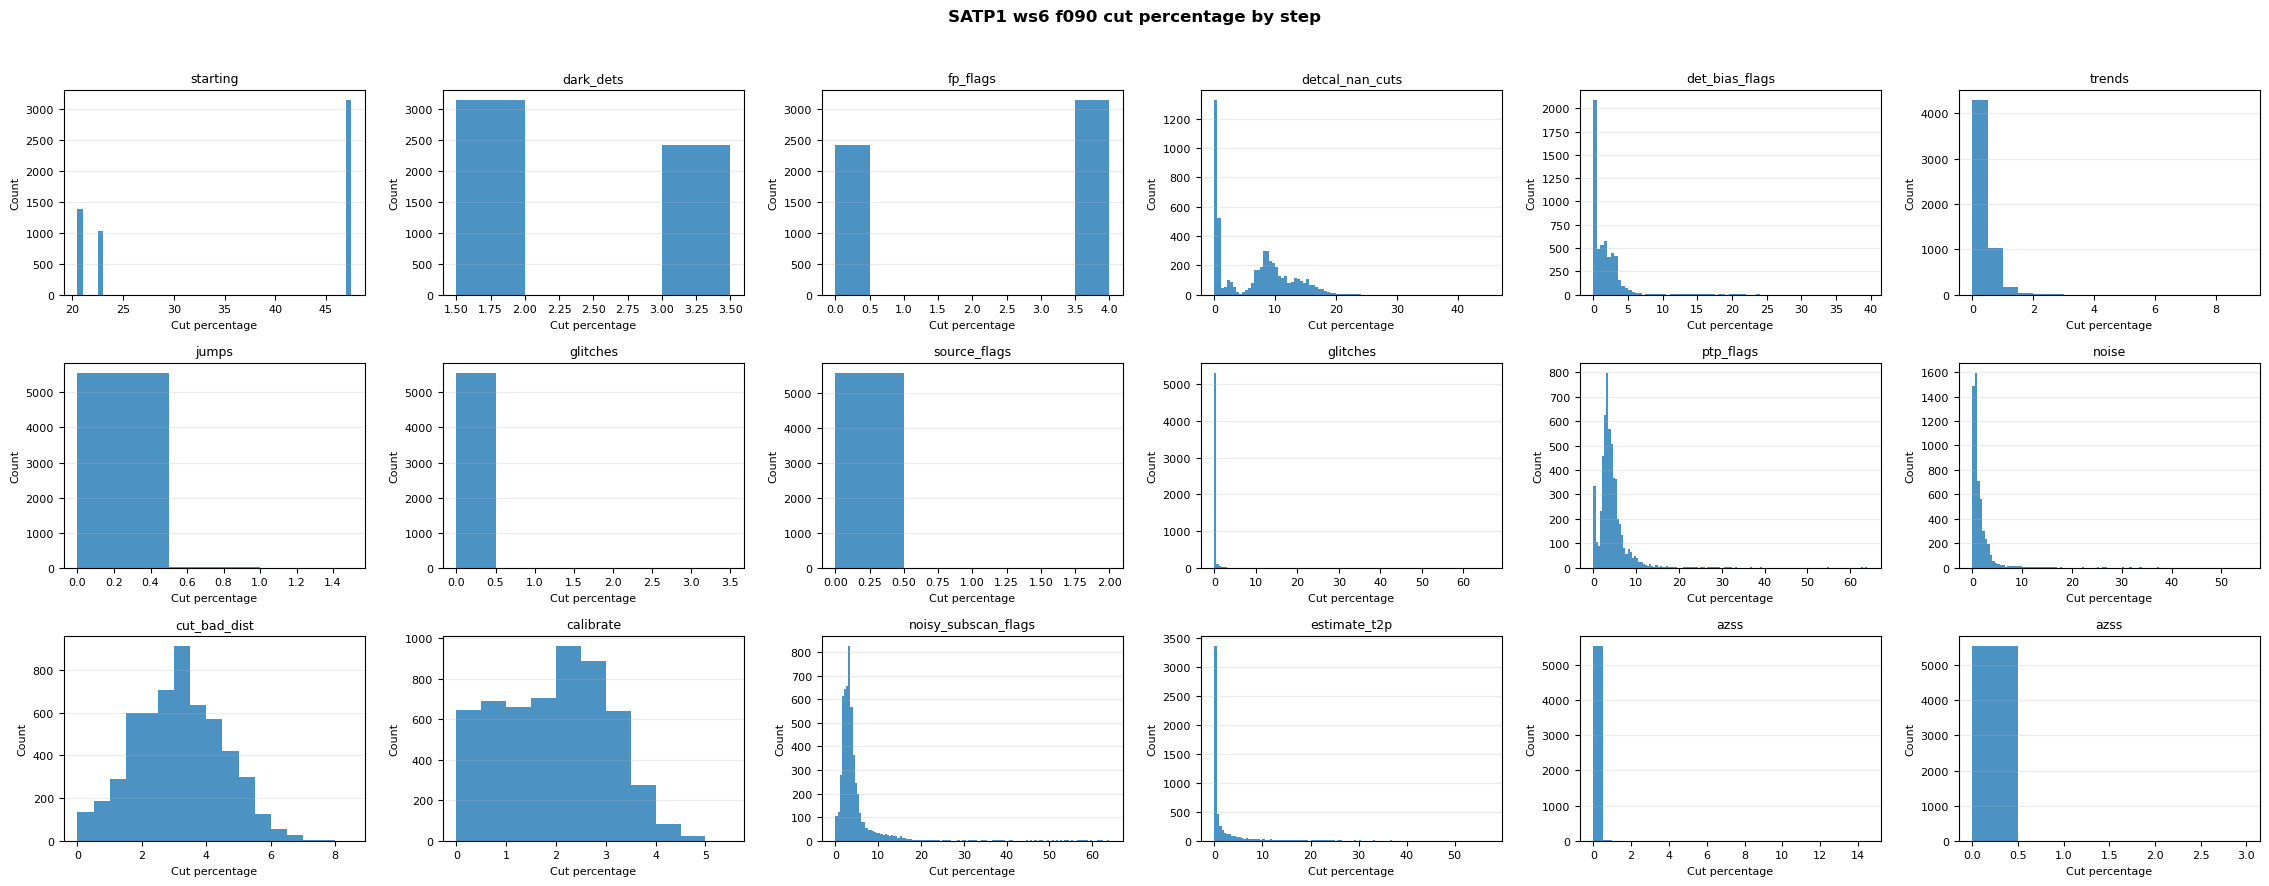

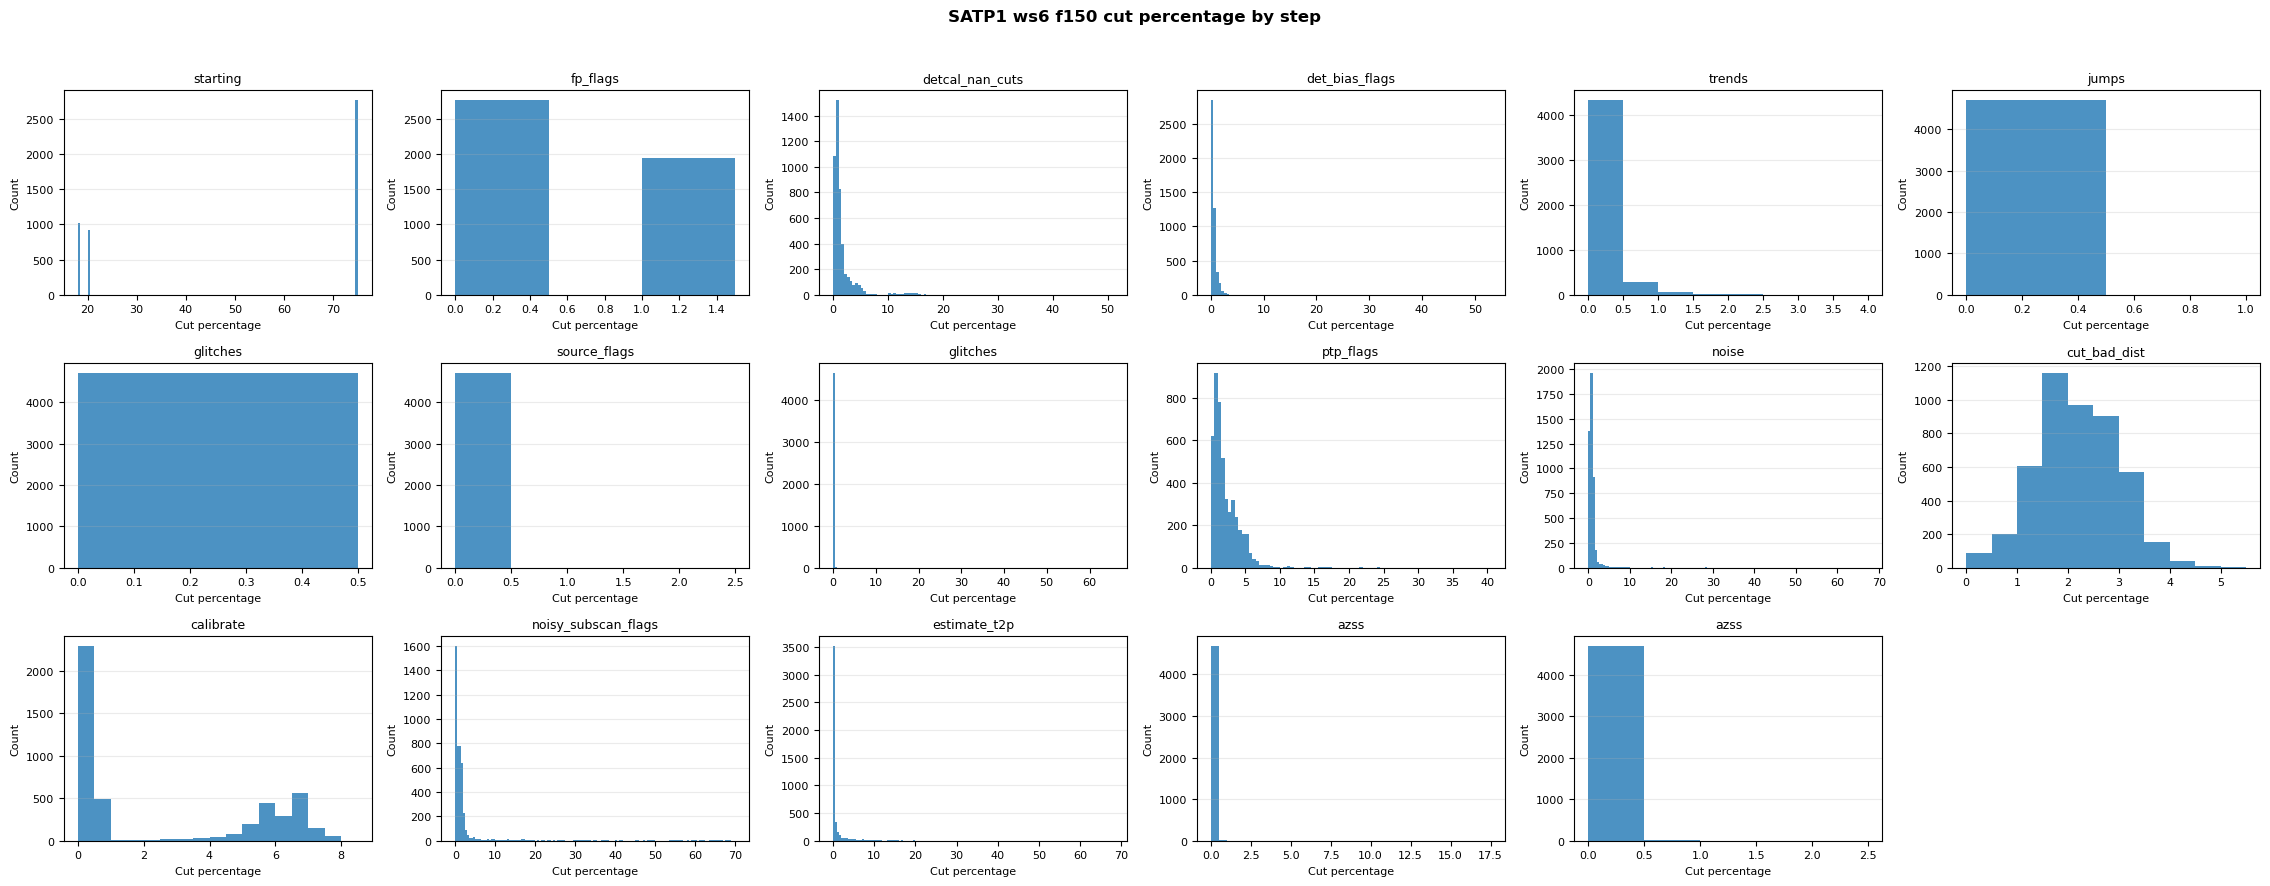

Rendered 14 wafer-band step-subplot cut histogram figures.


In [26]:
# One figure per wafer-band, with one subplot per non-zero-cut step.
# Each subplot uses 0.5%-step bins with auto-scaled min/max from local data.

import math

cuts_plot_rows = [row for row in bundle['obs_rows'] if row.get('success') == 1]
step_info = bundle['detector_steps']
step_labels = [step['step_name'] for step in step_info]
step_columns = [step['column'] for step in step_info]

output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

wafer_band_keys = sorted({
    (row.get('wafer'), row.get('band'))
    for row in cuts_plot_rows
    if row.get('wafer') is not None and row.get('band') is not None
})


def compute_per_obs_cuts(rows, s_idx, step_col, prev_col=None):
    """Return list of per-observation fraction cut for one step."""
    if s_idx == 0:
        return [
            (DETECTORS_PER_WAFER_PER_BAND - float(r[step_col])) / DETECTORS_PER_WAFER_PER_BAND
            for r in rows
            if r.get(step_col) is not None and not np.isnan(float(r[step_col]))
        ]
    return [
        (float(r[prev_col]) - float(r[step_col])) / DETECTORS_PER_WAFER_PER_BAND
        for r in rows
        if r.get(prev_col) is not None and r.get(step_col) is not None
        and not np.isnan(float(r[prev_col])) and not np.isnan(float(r[step_col]))
    ]


rendered = 0
for wafer, band in wafer_band_keys:
    wafer_rows = [
        r for r in cuts_plot_rows
        if r.get('wafer') == wafer and r.get('band') == band
    ]
    if not wafer_rows:
        continue

    # Non-zero-cut steps for this wafer-band.
    nonzero_step_indices = []
    for idx, step_col in enumerate(step_columns):
        prev_col = step_columns[idx - 1] if idx > 0 else None
        cuts_fraction = compute_per_obs_cuts(wafer_rows, idx, step_col, prev_col)
        if any(c > 0 for c in cuts_fraction):
            nonzero_step_indices.append(idx)

    if not nonzero_step_indices:
        continue

    n_steps = len(nonzero_step_indices)
    n_cols = min(6, n_steps)
    n_rows = math.ceil(n_steps / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(3.8 * n_cols, 3.0 * n_rows),
        squeeze=False,
    )

    for plot_pos, s_idx in enumerate(nonzero_step_indices):
        row_i, col_i = divmod(plot_pos, n_cols)
        ax = axes[row_i][col_i]

        step_col = step_columns[s_idx]
        prev_col = step_columns[s_idx - 1] if s_idx > 0 else None
        cuts_fraction = compute_per_obs_cuts(wafer_rows, s_idx, step_col, prev_col)
        cuts_percent = np.array([100.0 * c for c in cuts_fraction if not np.isnan(c)], dtype=float)

        if cuts_percent.size > 0:
            # Bin edges with 0.5% step, snapping min/max to 0.5-grid.
            lo = 0.5 * np.floor(np.min(cuts_percent) / 0.5)
            hi = 0.5 * np.ceil(np.max(cuts_percent) / 0.5)
            if hi <= lo:
                hi = lo + 0.5
            bin_edges = np.arange(lo, hi + 0.5, 0.5)
            if bin_edges.size < 2:
                bin_edges = np.array([lo, hi], dtype=float)

            ax.hist(
                cuts_percent,
                bins=bin_edges,
                alpha=0.8,
                color='C0',
                edgecolor='none',
            )

        ax.set_title(step_labels[s_idx], fontsize=9)
        ax.set_xlabel('Cut percentage', fontsize=8)
        ax.set_ylabel('Count', fontsize=8)
        ax.tick_params(labelsize=8)
        ax.grid(True, axis='y', alpha=0.25)

    # Hide unused axes.
    for plot_pos in range(n_steps, n_rows * n_cols):
        row_i, col_i = divmod(plot_pos, n_cols)
        axes[row_i][col_i].set_visible(False)

    fig.suptitle(
        f"{config.telescope.upper()} {wafer} {band} cut percentage by step",
        fontsize=12,
        fontweight='bold',
    )
    fig.tight_layout(rect=(0, 0, 1, 0.96))

    save_path = output_dir / f'{config.telescope}_{wafer}_{band}_cuts_histograms_by_step.png'
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    rendered += 1

print(f'Rendered {rendered} wafer-band step-subplot cut histogram figures.')


/tmp/ipykernel_3897819/3073491749.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = plt.cm.get_cmap('tab10', max(len(wafer_names), 1))
/tmp/ipykernel_3897819/3073491749.py:46: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  date = datetime.datetime.utcfromtimestamp(int(ts)).date()


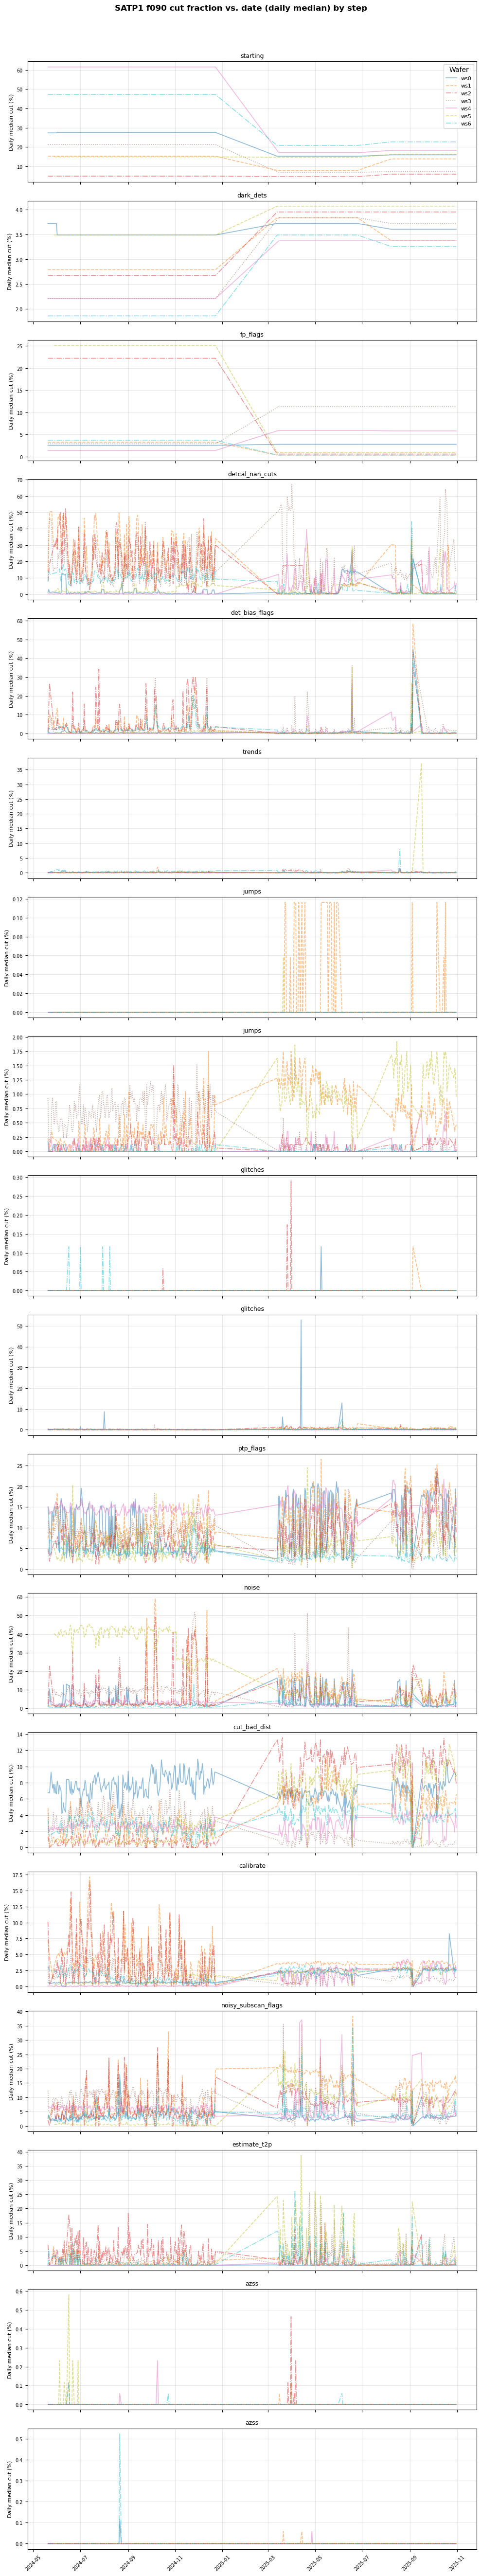

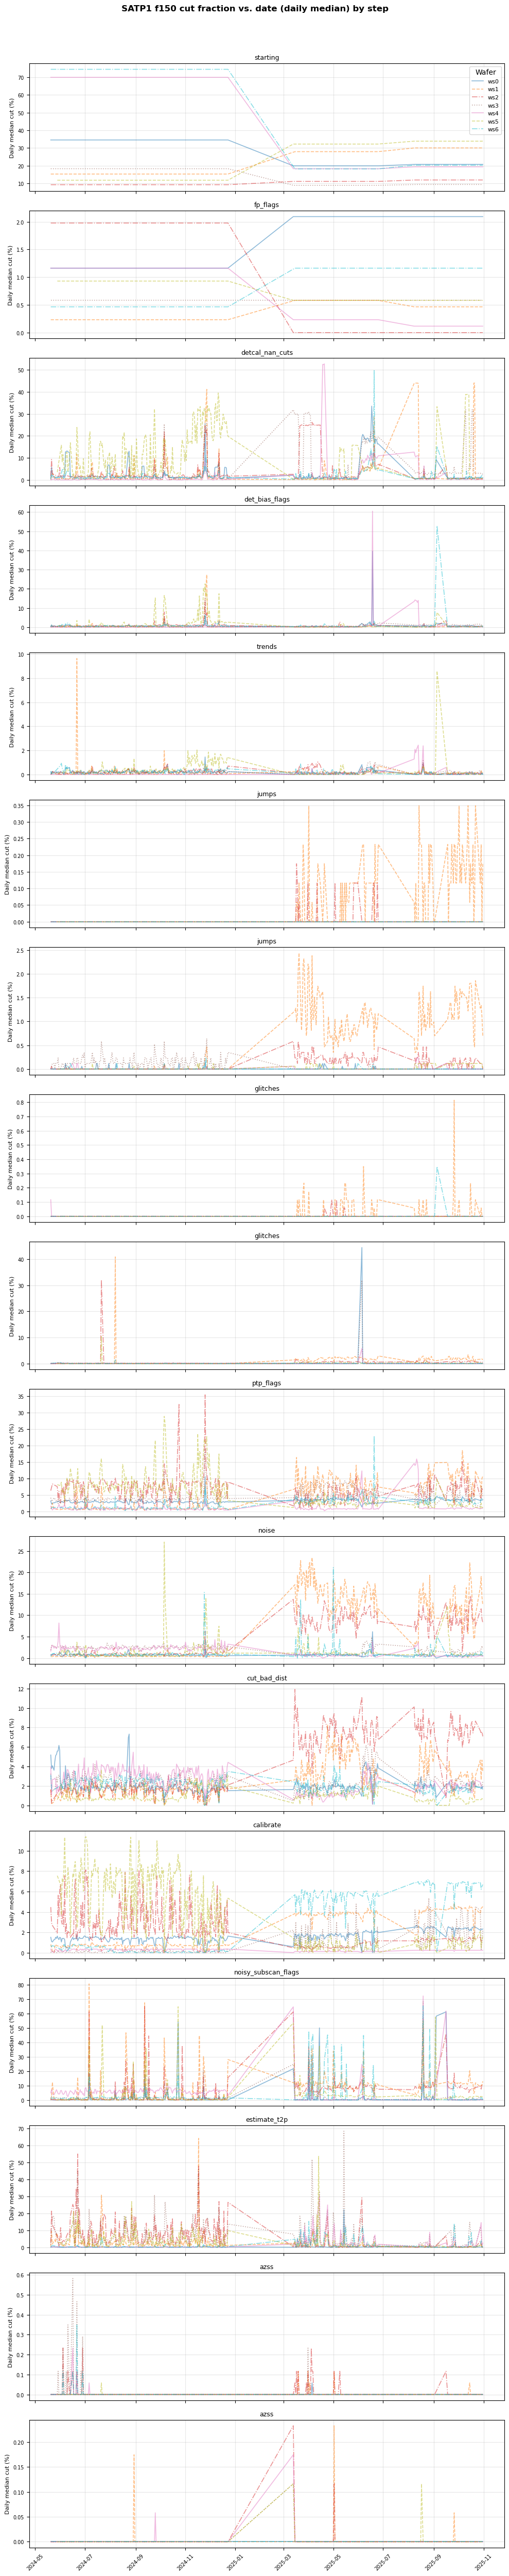

Rendered 2 band time-series cut fraction figures with daily aggregation (one per band, all wafers overlaid).


In [30]:
# Time-series of cut fraction per band across non-zero-cut steps, one curve per wafer

import datetime
import math

cuts_plot_rows = [row for row in bundle['obs_rows'] if row.get('success') == 1]
step_info = bundle['detector_steps']
step_labels = [step['step_name'] for step in step_info]
step_columns = [step['column'] for step in step_info]

output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

wafer_band_keys = sorted({
    (row.get('wafer'), row.get('band'))
    for row in cuts_plot_rows
    if row.get('wafer') is not None and row.get('band') is not None
})

bands_in_data = sorted({band for _, band in wafer_band_keys})
wafer_names = sorted({wafer for wafer, _ in wafer_band_keys})

# Wafer styles for visualization
line_styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
color_map = plt.cm.get_cmap('tab10', max(len(wafer_names), 1))
wafer_styles = {
    wafer: {
        'color': color_map(index % 10),
        'linestyle': line_styles[index % len(line_styles)],
        'marker': markers[index % len(markers)],
    }
    for index, wafer in enumerate(wafer_names)
}


def compute_timeseries_daily(wafer_rows, s_idx, step_col, prev_col=None):
    """Return list of (date, fraction_cut) aggregated by calendar day (daily median), sorted by date."""
    daily_fracs = {}  # date -> list of fractions for that day
    
    for r in wafer_rows:
        ts = extract_obs_timestamp(r.get('obs_id', ''))
        if ts is None:
            continue
        
        date = datetime.datetime.utcfromtimestamp(int(ts)).date()
        
        if s_idx == 0:
            if r.get(step_col) is not None and not np.isnan(float(r[step_col])):
                frac = (DETECTORS_PER_WAFER_PER_BAND - float(r[step_col])) / DETECTORS_PER_WAFER_PER_BAND
                if date not in daily_fracs:
                    daily_fracs[date] = []
                daily_fracs[date].append(frac)
        else:
            if r.get(prev_col) is not None and r.get(step_col) is not None:
                if not np.isnan(float(r[prev_col])) and not np.isnan(float(r[step_col])):
                    frac = (float(r[prev_col]) - float(r[step_col])) / DETECTORS_PER_WAFER_PER_BAND
                    if date not in daily_fracs:
                        daily_fracs[date] = []
                    daily_fracs[date].append(frac)
    
    # Compute daily median
    result = [(date, float(np.median(fracs))) for date, fracs in daily_fracs.items()]
    result.sort(key=lambda x: x[0])
    return result


rendered = 0
for band in bands_in_data:
    # Identify non-zero-cut steps for this band
    nonzero_step_indices = set()
    for wafer in wafer_names:
        band_rows = [r for r in cuts_plot_rows if r.get('wafer') == wafer and r.get('band') == band]
        if not band_rows:
            continue
        
        for idx, step_col in enumerate(step_columns):
            prev_col = step_columns[idx - 1] if idx > 0 else None
            ts_fracs = compute_timeseries_daily(band_rows, idx, step_col, prev_col)
            if any(frac > 0 for _, frac in ts_fracs):
                nonzero_step_indices.add(idx)
    
    if not nonzero_step_indices:
        continue
    
    nonzero_step_indices = sorted(nonzero_step_indices)
    n_steps = len(nonzero_step_indices)
    fig_h = max(3.0 * n_steps, 10)
    
    fig, axes = plt.subplots(
        n_steps,
        1,
        figsize=(10, fig_h),
        squeeze=False,
        sharex=True,
    )
    
    axes_flat = axes.flatten()
    
    for plot_pos, s_idx in enumerate(nonzero_step_indices):
        ax = axes_flat[plot_pos]
        
        step_col = step_columns[s_idx]
        prev_col = step_columns[s_idx - 1] if s_idx > 0 else None
        
        # Plot one curve per wafer
        for wafer in wafer_names:
            wafer_rows = [r for r in cuts_plot_rows if r.get('wafer') == wafer and r.get('band') == band]
            if not wafer_rows:
                continue
            
            ts_fracs = compute_timeseries_daily(wafer_rows, s_idx, step_col, prev_col)
            if not ts_fracs:
                continue
            
            dates, fracs = zip(*ts_fracs)
            dates = [datetime.datetime.combine(d, datetime.time.min) for d in dates]
            fracs_percent = [f * 100.0 for f in fracs]
            
            style = wafer_styles[wafer]
            ax.plot(
                dates,
                fracs_percent,
                label=wafer,
                color=style['color'],
                linestyle=style['linestyle'],
                linewidth=1.2,
                alpha=0.5,
            )
        
        ax.set_title(step_labels[s_idx], fontsize=9)
        ax.set_ylabel('Daily median cut (%)', fontsize=8)
        ax.tick_params(labelsize=7)
        ax.grid(True, alpha=0.3)
    
    # Rotate x-axis labels for readability on the last (bottom) subplot
    if len(axes_flat) > 0:
        axes_flat[-1].tick_params(axis='x', rotation=45)
    
    # Add legend on the first (top) subplot
    if len(axes_flat) > 0:
        axes_flat[0].legend(title='Wafer', fontsize=8, ncol=1, loc='best')
    
    fig.suptitle(
        f"{config.telescope.upper()} {band} cut fraction vs. date (daily median) by step",
        fontsize=12,
        fontweight='bold',
    )
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    
    save_path = output_dir / f'{config.telescope}_{band}_cuts_timeseries_daily_by_wafer.png'
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    rendered += 1

print(f'Rendered {rendered} band time-series cut fraction figures with daily aggregation (one per band, all wafers overlaid).')

In [ ]:
# Time-series of cut fraction: 2 figures (one per band), N_cut_steps rows x 7 columns (one per wafer)

import datetime

cuts_plot_rows = [row for row in bundle['obs_rows'] if row.get('success') == 1]
step_info = bundle['detector_steps']
step_labels = [step['step_name'] for step in step_info]
step_columns = [step['column'] for step in step_info]

output_dir = Path(config.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

wafer_band_keys = sorted({
    (row.get('wafer'), row.get('band'))
    for row in cuts_plot_rows
    if row.get('wafer') is not None and row.get('band') is not None
})

bands_in_data = sorted({band for _, band in wafer_band_keys})
wafer_names = sorted({wafer for wafer, _ in wafer_band_keys})


def compute_timeseries_daily(wafer_rows, s_idx, step_col, prev_col=None):
    """Return list of (date, fraction_cut) aggregated by calendar day (daily median), sorted by date."""
    daily_fracs = {}
    for r in wafer_rows:
        ts = extract_obs_timestamp(r.get('obs_id', ''))
        if ts is None:
            continue
        date = datetime.datetime.utcfromtimestamp(int(ts)).date()
        if s_idx == 0:
            if r.get(step_col) is not None and not np.isnan(float(r[step_col])):
                frac = (DETECTORS_PER_WAFER_PER_BAND - float(r[step_col])) / DETECTORS_PER_WAFER_PER_BAND
                daily_fracs.setdefault(date, []).append(frac)
        else:
            if r.get(prev_col) is not None and r.get(step_col) is not None:
                if not np.isnan(float(r[prev_col])) and not np.isnan(float(r[step_col])):
                    frac = (float(r[prev_col]) - float(r[step_col])) / DETECTORS_PER_WAFER_PER_BAND
                    daily_fracs.setdefault(date, []).append(frac)
    result = [(date, float(np.median(fracs))) for date, fracs in daily_fracs.items()]
    result.sort(key=lambda x: x[0])
    return result


rendered = 0
for band in bands_in_data:
    # Union of non-zero-cut step indices across all wafers for this band
    nonzero_step_indices = set()
    for wafer in wafer_names:
        band_rows = [r for r in cuts_plot_rows if r.get('wafer') == wafer and r.get('band') == band]
        for idx, step_col in enumerate(step_columns):
            prev_col = step_columns[idx - 1] if idx > 0 else None
            ts_fracs = compute_timeseries_daily(band_rows, idx, step_col, prev_col)
            if any(frac > 0 for _, frac in ts_fracs):
                nonzero_step_indices.add(idx)

    if not nonzero_step_indices:
        continue

    nonzero_step_indices = sorted(nonzero_step_indices)
    n_steps = len(nonzero_step_indices)
    n_wafers = len(wafer_names)

    fig, axes = plt.subplots(
        n_steps,
        n_wafers,
        figsize=(3.2 * n_wafers, 2.8 * n_steps),
        squeeze=False,
        sharex=True,
        sharey='row',
    )

    for row_pos, s_idx in enumerate(nonzero_step_indices):
        step_col = step_columns[s_idx]
        prev_col = step_columns[s_idx - 1] if s_idx > 0 else None

        for col_pos, wafer in enumerate(wafer_names):
            ax = axes[row_pos][col_pos]
            band_rows = [r for r in cuts_plot_rows if r.get('wafer') == wafer and r.get('band') == band]

            ts_fracs = compute_timeseries_daily(band_rows, s_idx, step_col, prev_col)
            if ts_fracs:
                dates, fracs = zip(*ts_fracs)
                dates = [datetime.datetime.combine(d, datetime.time.min) for d in dates]
                fracs_percent = [f * 100.0 for f in fracs]
                ax.plot(dates, fracs_percent, color='C0', linestyle='-', linewidth=1.0, alpha=0.7)

            ax.tick_params(labelsize=6)
            ax.grid(True, alpha=0.3)

            # Column headers (wafer names) on top row
            if row_pos == 0:
                ax.set_title(wafer, fontsize=9, fontweight='bold')
            # Row labels (step names) on leftmost column
            if col_pos == 0:
                ax.set_ylabel(step_labels[s_idx], fontsize=8)
            # Rotate x-axis tick labels on bottom row
            if row_pos == n_steps - 1:
                ax.tick_params(axis='x', rotation=45)

    fig.suptitle(
        f"{config.telescope.upper()} {band} cut fraction vs. date (daily median) — rows: steps, cols: wafers",
        fontsize=12,
        fontweight='bold',
    )
    fig.tight_layout(rect=(0, 0, 1, 0.97))

    save_path = output_dir / f'{config.telescope}_{band}_cuts_timeseries_daily_grid.png'
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    rendered += 1

print(f'Rendered {rendered} band grid time-series figures (N_steps rows × {len(wafer_names)} wafer columns).')

/tmp/ipykernel_3897819/1115996198.py:30: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  date = datetime.datetime.utcfromtimestamp(int(ts)).date()
